# DP 예산 역산 실험 — 통합 노트북

step5~step8에 흩어져 있던 실험을 **정의 구역 1개, 실행 구역 1개**로 합친 파일이다.

| 구역 | 내용 | 출처 |
|---|---|---|
| §1 | 공통 커널(통계, 신뢰구간, 검증, 그림 스타일) | 공통 |
| §2 | KCI 단일 시행 | step7 CODE 13 |
| §3 | KCI × n회 반복(+ 벡터화 엔진) | step7 CODE 29, step8 엔진 |
| §4 | KCI 메타 반복(반복의 반복) | 신규 |
| §5 | 제안 예산의 사후 검증기(KCI·역산 공용) | step7 CODE 34 |
| §6 | 최종 역산 모델(엄격 CAPRI v2) + 라운드별 원자료 | step7 CODE 24 |
| §7 | num_runs 스윕 + ridgeline | step7 CODE 62–65, step8 |
| §8 | 역산 seed 스윕 + beeswarm | 신규 |
| §9 | 실행, 검증, 내보내기 | — |

## 읽는 순서

1. **§0 설정** — 실험 상수는 전부 여기에만 있다. 다른 셀에는 상수를 직접 쓰지 않는다.
2. **§1~§8** — 정의만 한다. 이 구역의 셀은 아무 출력도 남기지 않으므로, 어느 함수가
   최종본인지 헷갈릴 일이 없다.
3. **§9** — 실행. 실험은 여기서만 돈다.

## 규약

- **한글 폰트**: §0에서 시스템 폰트를 자동 탐색해 등록하고(`setup_korean_font`),
  그림을 저장할 때마다 `_save()`가 글리프 누락 경고를 감시한다. 글자가 하나라도
  깨지면 저장을 실패시키므로, `outputs/`에 남은 PNG는 깨진 그림이 아니다.
  폰트를 못 찾는 환경(도커 등)에서는 노트북 옆 `fonts/NanumGothic.ttf`를 두면 된다.
- **NaN 정책**: `maxq`까지 가도 정지 규칙을 만족하지 못한 시행은 `k_stop = NaN`으로
  기록하고 평균에서 제외한다. 따라서 모든 집계는 **`converged_rate`를 반드시 함께**
  보고한다. `maxq`는 인위적 절단점이므로, 수렴률 없이 평균만 쓰면 결과를 왜곡한다.
- **검증 셀**은 `[VERIFICATION]`으로 표시했다. 벡터화 엔진이 스칼라 기준 구현을
  똑같이 재현하는지 확인한다. 여기가 실패하면 아래 숫자는 전부 신뢰할 수 없다.
- **신뢰구간**: 주 지표는 Wilson 구간이고, τ 임계값과 비교하는 자리에는
  Clopper–Pearson 구간을 함께 병기한다.


In [ ]:
# §0. 설정 — 실험 상수는 이 셀에만 둔다.
# ============================================================================
from __future__ import annotations

import math
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter, PercentFormatter, ScalarFormatter
from scipy import stats
from scipy.stats import beta

# ---- 실험 상수 -------------------------------------------------------------
ALPHA = 0.05      # 신뢰수준 95%
MAXQ = 500        # 질의 수 상한(여기 도달 = "미수렴")
EPS = 0.1         # 질의 1건당 예산
THRESHOLD = 0.05  # 목표 상대 신뢰구간 폭(구간 폭 / |평균|)
STREAK = 3        # 연속 충족 요구 횟수
TAU = 0.95        # 요구 성공 확률

# ---- 데이터셋 --------------------------------------------------------------
DATASETS = {
    "CardBase": {"path": Path("data/CardBase.csv"),      "column": "Credit_Limit"},
    "Bank":     {"path": Path("data/bank_exp.parquet"),  "column": "credit_limit"},
}

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---- 그림 스타일 -----------------------------------------------------------
PALETTE = {
    "kci":     "#2C6E8F",
    "inverse": "#B5563A",
    "pass":    "#3F7F5F",
    "fail":    "#C24B4B",
    "grid":    "#000000",
    "accent":  "#8A6D3B",
}
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 9.5,
    "axes.titlesize": 10,
    "axes.labelsize": 9.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.20,
    "grid.linewidth": 0.6,
    "legend.frameon": False,
    "figure.autolayout": False,
    "axes.unicode_minus": False,   # 마이너스는 ASCII로: 폰트에 없는 글리프 경고 방지
    # 로그축 눈금은 $10^{-1}$ 형태의 mathtext로 그려지고, 그 지수에 U+2212(진짜
    # 마이너스)가 들어간다. 한글 폰트에는 이 글자가 없어 조용히 네모가 되므로,
    # mathtext만 DejaVu 계열로 고정한다(이 경고는 파이썬 경고가 아니라 stderr로
    # 나가서 warnings 필터로는 잡히지 않는다).
    "mathtext.fontset": "dejavusans",
})

# ---- 한글 폰트 탐색 --------------------------------------------------------
# OS마다 폰트 위치가 다르므로 후보를 순서대로 확인한다. 노트북 옆 fonts/ 폴더를
# 가장 먼저 보기 때문에, 폰트를 함께 배포하면 어느 환경에서도 동일하게 렌더된다.
FONT_CANDIDATES = [
    Path("fonts/NanumGothic.ttf"),
    Path("fonts/NotoSansKR-Regular.ttf"),
    Path("C:/Windows/Fonts/malgun.ttf"),                       # Windows
    Path("C:/Windows/Fonts/malgunsl.ttf"),
    Path("/System/Library/Fonts/AppleSDGothicNeo.ttc"),        # macOS
    Path("/System/Library/Fonts/Supplemental/AppleGothic.ttf"),
    Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf"),   # Linux
    Path("/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf"),
    Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"),
    Path("/usr/share/fonts/truetype/noto/NotoSansCJK-Regular.ttc"),
]

# 확인용 글자: 한글 음절, 자모, 그리고 그림에 쓰는 기호들
GLYPH_PROBE = "가힣한글질의예산신뢰구간비율역산보장누적평균분포시행라운드검증결과값"


def find_korean_font(candidates=None):
    """한글 글리프가 실제로 들어 있는 폰트 파일을 찾는다.

    파일 존재 여부만으로는 부족하다. 폰트 파일이 있어도 한글 글리프가 없으면
    matplotlib은 'Glyph missing from font' 경고를 내고 네모(□)를 그린다.
    그래서 FT2Font로 '가'의 글리프 인덱스가 0이 아닌지까지 확인한다.

    반환: (경로, 폰트 이름, 글리프 수) — 못 찾으면 (None, None, 0)

    >>> path, name, nglyph = find_korean_font()
    >>> name is not None
    True
    """
    from matplotlib import font_manager as fm
    from matplotlib.ft2font import FT2Font

    for p in (candidates or FONT_CANDIDATES):
        p = Path(p)
        if not p.exists():
            continue
        try:
            ft = FT2Font(str(p))
        except Exception:
            continue                      # 폰트 파일이 아니거나 읽을 수 없음
        if ft.get_char_index(ord("가")) == 0:
            continue                      # 한글 글리프 없음 -> 건너뜀
        fm.fontManager.addfont(str(p))    # matplotlib 폰트 목록에 등록
        return str(p), fm.FontProperties(fname=str(p)).get_name(), ft.num_glyphs
    return None, None, 0


def setup_korean_font(verbose=True):
    """그림용 한글 폰트를 등록하고 rcParams에 지정한다.

    폰트를 못 찾으면 예외를 던진다. 조용히 DejaVu Sans로 넘어가면 결과 그림이
    전부 네모로 나오는데도 코드는 정상 종료하기 때문이다.

    >>> setup_korean_font(verbose=False)
    'NanumGothic'
    """
    path, name, nglyph = find_korean_font()
    if name is None:
        raise RuntimeError(
            "한글 폰트를 찾지 못했습니다. fonts/NanumGothic.ttf를 노트북 옆에 두거나 "
            "시스템에 나눔고딕/맑은 고딕/Noto Sans CJK KR을 설치하세요."
        )
    # 뒤쪽 후보는 기호(—, ×, ≤ 등)가 빠졌을 때의 보조 폰트
    plt.rcParams["font.family"] = [name, "DejaVu Sans"]
    plt.rcParams["axes.unicode_minus"] = False

    # 등록한 폰트가 실제로 확인용 글자를 전부 그릴 수 있는지 검사
    from matplotlib.ft2font import FT2Font
    ft = FT2Font(path)
    missing = sorted({c for c in GLYPH_PROBE if ft.get_char_index(ord(c)) == 0})
    if missing:
        raise RuntimeError(f"폰트 {name}에 없는 글자: {''.join(missing)}")

    if verbose:
        print(f"한글 폰트: {name}  ({Path(path).name}, 글리프 {nglyph:,}개)")
        print(f"  font.family = {plt.rcParams['font.family']}")
        print(f"  확인용 글자 {len(GLYPH_PROBE)}자 전부 정상")
    return name


setup_korean_font()

print(f"설정: EPS={EPS}, THRESHOLD={THRESHOLD}, STREAK={STREAK}, MAXQ={MAXQ}, TAU={TAU}")

: 

In [ ]:
# §1. 공통 커널
# ============================================================================


def load_dataset(path, column):
    """CSV/Parquet에서 숫자 열을 읽어 엔진이 쓰는 dict 형태로 만든다.

    delta는 전역 민감도 (최대-최소)/n 이다. 평균 질의에 대한 라플라스 척도는
    delta/eps 가 된다.

    >>> DATA = load_dataset("data/CardBase.csv", "Credit_Limit")
    >>> DATA["n"], round(DATA["true_mean"], 1), DATA["delta"]
    (500, 252614.0, 1794.0)
    """
    path = Path(path)
    if path.suffix.lower() == ".csv":
        df = pd.read_csv(path)
    elif path.suffix.lower() == ".parquet":
        df = pd.read_parquet(path)
    else:
        raise ValueError(f"지원하지 않는 파일 형식: {path}")

    if column not in df.columns:
        raise KeyError(f"{path}에 {column!r} 열이 없습니다")

    x = pd.to_numeric(df[column], errors="coerce").dropna().to_numpy(float)
    if x.size == 0:
        raise ValueError(f"{path}의 {column!r} 열에 숫자가 없습니다")

    n = len(x)
    return {
        "x": x,
        "n": n,
        "true_mean": float(x.mean()),
        "min": float(x.min()),
        "max": float(x.max()),
        "delta": float((x.max() - x.min()) / n),
    }


def synthetic_dataset(n=500, true_mean=252614.0, delta=1794.0, seed=0):
    """CSV/Parquet 파일이 없을 때 쓰는 대체 데이터.

    엔진은 true_mean과 delta만 소비하므로, 이 두 값을 지정하면 실험이 그대로
    재현된다.

    >>> d = synthetic_dataset(n=500, delta=1794.0, seed=1)
    >>> d["n"], d["delta"]
    (500, 1794.0)
    """
    rng = np.random.default_rng(seed)
    x = true_mean + rng.normal(0.0, true_mean * 0.35, size=n)
    x = np.clip(x, true_mean - delta * n / 2, true_mean + delta * n / 2)
    x = x - x.mean() + true_mean          # 평균을 true_mean에 정확히 고정
    span = delta * n
    x = np.clip(x, true_mean - span / 2, true_mean + span / 2)
    return {"x": x, "n": n, "true_mean": float(x.mean()),
            "min": float(x.min()), "max": float(x.max()), "delta": float(delta)}


def get_data(name="CardBase", fallback_synthetic=True):
    """DATASETS[name]을 읽고, 파일이 없으면 합성 데이터로 대체한다.

    >>> DATA = get_data("CardBase")
    >>> DATA["n"]
    500
    """
    cfg = DATASETS[name]
    if Path(cfg["path"]).exists():
        return load_dataset(cfg["path"], cfg["column"])
    if not fallback_synthetic:
        raise FileNotFoundError(cfg["path"])
    print(f"[알림] {cfg['path']} 없음 -> 합성 데이터 사용 "
          f"(true_mean/delta만 소비됨)")
    if name == "Bank":
        return synthetic_dataset(n=6744, true_mean=9074.479537, delta=4.904656, seed=1)
    return synthetic_dataset(n=500, true_mean=252614.0, delta=1794.0, seed=0)


def _statistics(values, true_mean, alpha=ALPHA):
    """누적 평균, 표본분산, t 기반 95% 신뢰구간, 상대 폭을 계산한다."""
    values = np.asarray(values, dtype=float)
    k = len(values)
    cumulative_mean = float(values.mean())

    if k < 2:
        return {
            "k": k, "response": float(values[-1]),
            "cumulative_mean": cumulative_mean,
            "sample_std": np.nan, "standard_error": np.nan,
            "moe": np.nan, "ci_lo": np.nan, "ci_hi": np.nan,
            "ci_width": np.nan, "relative_width": np.nan,
            "hit": False, "covered": pd.NA,
        }

    sample_std = float(values.std(ddof=1))
    standard_error = sample_std / np.sqrt(k)
    t_value = stats.t.ppf(1 - alpha / 2, df=k - 1)
    moe = float(t_value * standard_error)
    ci_lo = cumulative_mean - moe
    ci_hi = cumulative_mean + moe
    ci_width = float(2 * moe)
    relative_width = float(ci_width / abs(cumulative_mean)) if cumulative_mean != 0 else np.inf
    covered = bool(ci_lo <= true_mean <= ci_hi)

    return {
        "k": k, "response": float(values[-1]),
        "cumulative_mean": cumulative_mean,
        "sample_std": sample_std, "standard_error": standard_error,
        "moe": moe, "ci_lo": ci_lo, "ci_hi": ci_hi,
        "ci_width": ci_width, "relative_width": relative_width,
        "hit": False, "covered": covered,
    }


def _overlap_from_ci(ci_lo, ci_hi, delta):
    """-delta만큼 평행이동한 이웃 구간과의 겹침(보조 지표)."""
    if not (np.isfinite(ci_lo) and np.isfinite(ci_hi)):
        return {"adj_ci_lo": np.nan, "adj_ci_hi": np.nan,
                "overlap_width": np.nan, "overlap_ratio": np.nan,
                "width_to_delta": np.nan}
    adj_ci_lo = ci_lo - delta
    adj_ci_hi = ci_hi - delta
    overlap_width = max(0.0, min(ci_hi, adj_ci_hi) - max(ci_lo, adj_ci_lo))
    ci_width = ci_hi - ci_lo
    return {
        "adj_ci_lo": adj_ci_lo,
        "adj_ci_hi": adj_ci_hi,
        "overlap_width": overlap_width,
        "overlap_ratio": overlap_width / ci_width if ci_width > 0 else np.nan,
        "width_to_delta": ci_width / delta if delta > 0 else np.nan,
    }


def _validate_inputs(eps, threshold, streak_required, maxq):
    """인자 검증: 잘못된 설정으로 조용히 도는 것을 막는다."""
    if eps <= 0:
        raise ValueError("eps는 0보다 커야 합니다")
    if threshold <= 0:
        raise ValueError("threshold는 0보다 커야 합니다")
    if streak_required < 1:
        raise ValueError("streak_required는 1 이상이어야 합니다")
    if maxq < 2:
        raise ValueError("maxq는 2 이상이어야 합니다")


def _t_table(maxq, alpha=ALPHA):
    """k = 1..maxq에 대한 t 분위수(벡터화 엔진이 한 번만 계산해 재사용).

    >>> len(_t_table(10)), round(float(_t_table(10)[4]), 4)   # k=5, df=4
    (10, 2.7764)
    """
    k = np.arange(1, maxq + 1, dtype=float)
    t = np.full(maxq, np.nan)
    t[1:] = stats.t.ppf(1 - alpha / 2, df=k[1:] - 1)
    return t


def wilson_ci(k, n, z=1.959963984540054):
    """Wilson 점수 구간: 0/1 경계에서도 유효하고 포함확률이 명목수준에 가깝다.

    >>> [round(v, 4) for v in wilson_ci(477, 500)]
    [0.9319, 0.9692]
    """
    if n <= 0:
        return (np.nan, np.nan)
    p = k / n
    denom = 1.0 + z * z / n
    centre = (p + z * z / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return (max(0.0, centre - half), min(1.0, centre + half))


def clopper_pearson_ci(k, n, alpha=ALPHA):
    """Clopper–Pearson 정확 구간: 포함확률이 명목수준 이상(보수적).

    >>> [round(v, 4) for v in clopper_pearson_ci(477, 500)]
    [0.9318, 0.9706]
    """
    if n <= 0:
        return (np.nan, np.nan)
    lo = 0.0 if k == 0 else float(beta.ppf(alpha / 2, k, n - k + 1))
    hi = 1.0 if k == n else float(beta.ppf(1 - alpha / 2, k + 1, n - k))
    return (lo, hi)


def _style(ax):
    """축 공통 스타일."""
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="both", alpha=0.18, linewidth=0.6)
    return ax


def _save(fig, name):
    """그림을 outputs/에 저장하고, 글리프 누락이 있으면 저장 자체를 실패시킨다.

    matplotlib은 폰트에 없는 글자를 만나면 경고만 내고 네모를 그린 채로 파일을
    남긴다. 그런 그림이 결과 폴더에 섞이면 조용히 잘못된 자료가 되므로,
    저장 시점에 경고를 잡아 예외로 바꾼다.

    >>> p = _save(fig, "demo")     # -> outputs/demo.png
    """
    path = OUTPUT_DIR / f"{name}.png"
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        fig.savefig(path, bbox_inches="tight")
    missing = [str(w.message) for w in caught if "missing from font" in str(w.message)]
    if missing:
        raise RuntimeError(
            f"[{name}] 글자가 깨졌습니다 — 폰트에 없는 글리프: "
            + " | ".join(sorted(set(missing))[:5])
        )
    return path


print("§1 공통 커널 준비 완료")

: 

In [ ]:
# §2. KCI 단일 시행 — 질의를 1건씩 추가하며 streak 규칙 적용
# ============================================================================


def run_kci_live(data, eps=EPS, threshold=THRESHOLD, streak_required=STREAK,
                 maxq=MAXQ, alpha=ALPHA, seed=0, verbose=False):
    """KCI 시행 1회.

    질의를 순차적으로 던지고, 상대 폭이 `threshold` 미만인 상태가 `streak_required`
    회 연속으로 유지되는 첫 k에서 멈춘다. 한 번이라도 어긋나면 streak은 0으로
    초기화된다. `maxq`까지 가도 규칙을 만족하지 못하면 그 시행은 절단된 것으로
    보고 converged=False, k_stop=NaN 으로 기록한다.

    인자
      data            : load_dataset()의 반환값(true_mean과 delta만 사용)
      eps             : 질의 1건당 예산
      threshold       : 목표 상대 신뢰구간 폭
      streak_required : 요구되는 연속 충족 횟수
      maxq            : 질의 수 상한(인위적 절단점)
      seed            : 난수 시드

    반환
      (history DataFrame, final dict)
      history : query_k, response, cumulative_mean, ci_lo, ci_hi, relative_width,
                hit, streak_count, actual_eps_total, covered
      final   : converged, k_stop, eps_total, relative_width, covered, seed

    >>> DATA = get_data("CardBase")
    >>> hist, final = run_kci_live(DATA, seed=0)
    >>> final["converged"], int(final["k_stop"])
    (True, 77)
    """
    _validate_inputs(eps, threshold, streak_required, maxq)
    scale = data["delta"] / eps
    rng = np.random.default_rng(int(seed))

    responses, rows = [], []
    streak = 0
    k_stop = None

    for k in range(1, maxq + 1):
        responses.append(float(data["true_mean"] + rng.laplace(0.0, scale)))

        row = _statistics(responses, data["true_mean"], alpha)
        row.update(_overlap_from_ci(row["ci_lo"], row["ci_hi"], data["delta"]))

        hit = bool(np.isfinite(row["relative_width"]) and row["relative_width"] < threshold)
        streak = streak + 1 if hit else 0
        row.update({"query_k": k, "hit": hit, "streak_count": streak,
                    "actual_eps_total": eps * k})
        rows.append(row)

        if streak >= streak_required:
            k_stop = k
            break

    hist = pd.DataFrame(rows)
    converged = k_stop is not None
    last = hist.iloc[-1]

    final = {
        "converged": converged,
        "k_stop": int(k_stop) if converged else np.nan,
        "eps_total": float(eps * k_stop) if converged else np.nan,
        "k_last": int(last["query_k"]),
        "relative_width": float(last["relative_width"]),
        "streak_count": int(last["streak_count"]),
        "covered": None if pd.isna(last["covered"]) else bool(last["covered"]),
        "seed": int(seed),
        "eps": float(eps),
        "threshold": float(threshold),
    }
    if verbose:
        print(f"[KCI seed={seed}] 수렴={converged} k_stop={final['k_stop']} "
              f"eps_total={final['eps_total']}")
    return hist, final

: 

In [ ]:
# §3. KCI × n회 반복(+ 벡터화 엔진)
# ============================================================================


def _kci_batch(true_mean, delta, eps, threshold, streak_required, maxq,
               alpha, seeds, keep_matrix=False):
    """KCI 시행들을 시행 축으로 벡터화한다(내부 헬퍼).

    스칼라 구현과의 동등성
      - 각 시행은 자기 rng로 laplace(0, scale, size=maxq)를 한 번에 뽑는다. 이는
        스칼라 호출 maxq번과 같은 난수열을 만든다(VERIFICATION-A에서 확인).
      - 상대 폭은 k >= 2일 때만 유한하다. k=1은 NaN으로 남아 hit=False가 되고,
        이는 스칼라 버전과 정확히 같다.
      - streak은 마지막 실패 위치를 추적해 계산한다. run[i] = i - last_fail[i]가
        곧 연속 충족 횟수다.

    반환 dict: k_stop(절단이면 0), converged, eps_total, relw_stop,
               covered_stop, k_last, 그리고 선택적으로 relw / covered 행렬.
    """
    seeds = np.atleast_1d(np.asarray(seeds, dtype=np.int64))
    n = seeds.size
    scale = delta / eps
    t = _t_table(maxq, alpha)

    noise = np.empty((n, maxq), dtype=float)
    for i, s in enumerate(seeds):
        noise[i] = np.random.default_rng(int(s)).laplace(0.0, scale, size=maxq)
    resp = true_mean + noise
    del noise

    csum = np.cumsum(resp, axis=1)
    k = np.arange(1, maxq + 1, dtype=float)
    cmean = csum / k
    csq = np.cumsum(resp * resp, axis=1)
    var = np.empty_like(resp)
    var[:, 0] = np.nan
    var[:, 1:] = (csq[:, 1:] - k[1:] * cmean[:, 1:] ** 2) / (k[1:] - 1)
    std = np.sqrt(np.clip(var, 0.0, None))
    del csq, var

    se = std / np.sqrt(k)
    moe = t[None, :] * se
    width = 2.0 * moe
    with np.errstate(invalid="ignore", divide="ignore"):
        relw = np.where(np.abs(cmean) > 0, width / np.abs(cmean), np.inf)
    del width, moe, se, std

    hit = np.isfinite(relw) & (relw < threshold)

    # streak: 마지막 실패 위치를 추적
    idx = np.arange(maxq)
    last_fail = np.maximum.accumulate(np.where(hit, -1, idx), axis=1)
    run = idx[None, :] - last_fail
    ok = run >= streak_required

    any_ok = ok.any(axis=1)
    stop0 = np.where(any_ok, ok.argmax(axis=1), maxq - 1)      # 0부터 시작
    converged = any_ok

    ci_half = t[None, :] * np.sqrt(np.clip(
        (np.cumsum(resp * resp, axis=1) - k * cmean ** 2) / np.maximum(k - 1, 1), 0, None)
    ) / np.sqrt(k)
    covered_mat = (cmean - ci_half <= true_mean) & (true_mean <= cmean + ci_half)
    del ci_half

    rows = np.arange(n)
    relw_stop = relw[rows, stop0]
    covered_stop = covered_mat[rows, stop0]
    k_stop = np.where(converged, stop0 + 1, 0)

    out = {
        "k_stop": k_stop.astype(int),
        "converged": converged,
        "eps_total": np.where(converged, eps * k_stop, np.nan),
        "relw_stop": relw_stop,
        "covered_stop": covered_stop,
        "k_last": np.where(converged, k_stop, maxq),
    }
    if keep_matrix:
        out["relw"] = relw
        out["covered"] = covered_mat
    return out


def _summarize_eps(values, label="eps_total"):
    """NaN(절단)을 제외한 분포 요약. n_valid는 항상 함께 반환한다."""
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]
    if v.size == 0:
        return {f"{label}_n_valid": 0, f"{label}_mean": np.nan, f"{label}_median": np.nan,
                f"{label}_std": np.nan, f"{label}_q25": np.nan, f"{label}_q75": np.nan,
                f"{label}_iqr": np.nan, f"{label}_q95": np.nan}
    q25, q50, q75, q95 = np.quantile(v, [0.25, 0.5, 0.75, 0.95])
    return {
        f"{label}_n_valid": int(v.size),
        f"{label}_mean": float(v.mean()),
        f"{label}_median": float(q50),
        f"{label}_std": float(v.std(ddof=1)) if v.size > 1 else 0.0,
        f"{label}_q25": float(q25),
        f"{label}_q75": float(q75),
        f"{label}_iqr": float(q75 - q25),
        f"{label}_q95": float(q95),
    }


def run_kci_repeated(data, n_reps=500, eps=EPS, threshold=THRESHOLD,
                     streak_required=STREAK, maxq=MAXQ, alpha=ALPHA,
                     seed0=2026, keep_trajectories=False):
    """KCI 시행을 독립 시드로 n_reps회 반복한다.

    여기서 나오는 eps_total_mean이 논문에서 KCI 방식이 제안하는 "총예산"이다.
    절단된 시행은 평균에서 제외되므로, 이 값은 반드시 converged_rate와 함께
    읽어야 한다.

    인자
      n_reps            : 반복 횟수(논문 설정: 500)
      seed0             : i번째 시행은 seed0 + i를 쓴다
      keep_trajectories : 시행별 상대 폭 행렬도 반환할지(메모리 주의)

    반환
      (trials_df, summary_dict, traj_matrix 또는 None)
      trials_df : rep, seed, converged, k_stop, eps_total, relw_stop, covered
      summary   : eps_total_* 집계 + converged_rate + covered_rate + censored_rate

    >>> DATA = get_data("CardBase")
    >>> trials, s, _ = run_kci_repeated(DATA, n_reps=500, seed0=2026)
    >>> round(s["eps_total_mean"], 2), round(s["converged_rate"], 3)   # doctest: +SKIP
    (6.14, 1.0)
    """
    _validate_inputs(eps, threshold, streak_required, maxq)
    if n_reps < 1:
        raise ValueError("n_reps는 1 이상이어야 합니다")

    seeds = seed0 + np.arange(n_reps, dtype=np.int64)
    t0 = time.perf_counter()
    out = _kci_batch(data["true_mean"], data["delta"], eps, threshold,
                     streak_required, maxq, alpha, seeds,
                     keep_matrix=keep_trajectories)
    elapsed = time.perf_counter() - t0

    trials = pd.DataFrame({
        "rep": np.arange(1, n_reps + 1),
        "seed": seeds,
        "converged": out["converged"],
        "k_stop": np.where(out["converged"], out["k_stop"], np.nan),
        "k_last": out["k_last"],
        "eps_total": out["eps_total"],
        "relw_stop": out["relw_stop"],
        "covered": out["covered_stop"],
    })

    summary = {
        "n_reps": int(n_reps),
        "eps": float(eps),
        "threshold": float(threshold),
        "streak_required": int(streak_required),
        "maxq": int(maxq),
        "converged_rate": float(np.mean(out["converged"])),
        "censored_rate": float(1.0 - np.mean(out["converged"])),
        "covered_rate": float(np.mean(out["covered_stop"])),
        "elapsed_sec": round(elapsed, 3),
        **_summarize_eps(out["eps_total"]),
        **_summarize_eps(out["k_stop"], label="k_stop"),
    }
    traj = out.get("relw") if keep_trajectories else None
    return trials, summary, traj

In [5]:
# ============================================================================
# §3-b. KCI 그림
# ============================================================================


def plot_kci_live(hist, final, title=None, ax_pair=None):
    """단일 시행 궤적: 누적 평균과 95% 신뢰구간, 그리고 목표 대비 상대 폭.

    오른쪽 패널의 음영은 폭 목표를 만족한 질의를 표시한다. 그런 질의가 3회
    연속되는 지점에서 시행이 멈춘다.

    >>> DATA = get_data("CardBase")
    >>> hist, final = run_kci_live(DATA, seed=7)
    >>> fig, axes = plot_kci_live(hist, final)
    """
    if ax_pair is None:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.0, 3.9))
    else:
        fig, (ax1, ax2) = ax_pair

    k = hist["query_k"].to_numpy()
    m = hist["cumulative_mean"].to_numpy()

    ax1.fill_between(k, hist["ci_lo"], hist["ci_hi"], color=PALETTE["kci"], alpha=0.18,
                     linewidth=0, label="95% 신뢰구간")
    ax1.plot(k, m, color=PALETTE["kci"], lw=1.6, label="누적 평균")
    ax1.set_xlabel("질의 수 k")
    ax1.set_ylabel("추정 평균")
    ax1.legend(loc="lower right", fontsize=8)
    _style(ax1)

    rw = hist["relative_width"].to_numpy()
    ax2.plot(k, rw, color=PALETTE["kci"], lw=1.4)
    ax2.axhline(final["threshold"], color=PALETTE["fail"], lw=1.0, ls="--",
                label=f"목표 {final['threshold']:.0%}")

    hit = hist["hit"].to_numpy()
    if hit.any():
        ax2.fill_between(k, 0, np.nanmax(rw[np.isfinite(rw)]) * 1.05, where=hit,
                         color=PALETTE["pass"], alpha=0.12, linewidth=0,
                         label="조건 충족")
    if final["converged"]:
        ax2.axvline(final["k_stop"], color="0.25", lw=1.0, ls=":")
        ax2.annotate(f"정지 k={int(final['k_stop'])}\n예산 {final['eps_total']:.1f}",
                     xy=(final["k_stop"], final["threshold"]), xytext=(6, 14),
                     textcoords="offset points", fontsize=8, color="0.25")
    ax2.set_ylim(bottom=0)
    ax2.set_xlabel("질의 수 k")
    ax2.set_ylabel("상대 신뢰구간 폭")
    ax2.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax2.legend(loc="upper right", fontsize=8)
    _style(ax2)

    ax1.set_title(title or f"KCI 단일 시행 (seed={final['seed']})", fontsize=10)
    fig.tight_layout()
    return fig, (ax1, ax2)


def plot_kci_ecdf(trials, summary=None, ref_lines=None, title=None):
    """[주 그림] 정지 예산의 경험적 누적분포(ECDF).

    이 한 패널에서 세 가지를 읽는다.
      1) 95% 분위를 곡선에서 바로 읽을 수 있어 "9.30과의 비교"가 한 점 확인이 된다.
      2) 절단된 시행이 하나라도 있으면 곡선이 1.0에 닿지 않으므로, 절단을 숨길 수
         없다.
      3) 평균과 중앙값이 꼬리와 같은 축에 있어 꼬리의 길이가 그대로 보인다.

    >>> trials, s, _ = run_kci_repeated(DATA, n_reps=500)
    >>> fig, ax = plot_kci_ecdf(trials, s, ref_lines={"역산 보장예산 9.30": 9.30})
    """
    v = np.sort(trials["eps_total"].dropna().to_numpy(float))
    v = np.array(v, dtype=float, copy=True)
    n_total = len(trials)
    n_valid = v.size

    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    if n_valid:
        y = np.arange(1, n_valid + 1) / n_valid
        ax.step(v, y, where="post", color=PALETTE["kci"], lw=1.9, label="ECDF (수렴 시행)")
        q95 = np.quantile(v, 0.95)
        ax.vlines(q95, 0, 0.95, color=PALETTE["accent"], lw=1.0, ls="--")
        ax.plot([q95], [0.95], "o", ms=5, color=PALETTE["accent"])
        ax.annotate(f"95% 분위 {q95:.2f}", xy=(q95, 0.95), xytext=(-10, 14),
                    textcoords="offset points", ha="right", va="bottom", fontsize=8,
                    color=PALETTE["accent"])
        m = float(v.mean())
        ax.vlines(m, 0, 0.5, color="0.35", lw=1.0, ls=":")
        ax.annotate(f"평균 {m:.2f}", xy=(m, 0.5), xytext=(4, -12),
                    textcoords="offset points", fontsize=8, color="0.35")

    if ref_lines:
        for i, (label, x) in enumerate(ref_lines.items()):
            ax.axvline(x, color=PALETTE["inverse"], lw=1.2, ls=(0, (4, 3)),
                       alpha=0.9 if i == 0 else 0.6)
            ax.annotate(label, xy=(x, 0.06 + 0.07 * i), xytext=(3, 0),
                        textcoords="offset points", fontsize=8,
                        color=PALETTE["inverse"], rotation=90, va="bottom")

    if n_valid < n_total:
        ax.annotate(f"절단 {n_total - n_valid}건 (maxq 도달)\n"
                    "-> 곡선이 1.0에 닿지 않음",
                    xy=(0.98, 0.42), xycoords="axes fraction", ha="right", fontsize=8,
                    color=PALETTE["fail"])

    ax.set_ylim(0, 1.04)
    ax.set_xlabel("소모한 총예산 ε_total")
    ax.set_ylabel("누적 비율")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ttl = title or "KCI 반복: 정지 예산의 경험적 누적분포"
    if summary is not None:
        ttl += f"  (수렴 {summary['converged_rate']:.1%}, n={summary['n_reps']})"
    ax.set_title(ttl, fontsize=10)
    ax.legend(loc="lower right", fontsize=8)
    _style(ax)
    fig.tight_layout()
    return fig, ax


def plot_kci_hist(trials, summary=None, bins=40, title=None):
    """정지 예산의 히스토그램 + 커널밀도(보조 그림).

    절단된 시행은 maxq*eps 위치에 막대로 나타나므로, 이 그림은 단독이 아니라
    ECDF와 함께 읽는다.

    >>> fig, ax = plot_kci_hist(trials, s)
    """
    v = trials["eps_total"].dropna().to_numpy(float)
    fig, ax = plt.subplots(figsize=(6.8, 4.0))
    if v.size:
        ax.hist(v, bins=bins, color=PALETTE["kci"], alpha=0.55, edgecolor="white",
                linewidth=0.6, density=True, label="히스토그램")
        if v.size > 5 and v.std() > 0:
            kde = stats.gaussian_kde(v)
            xs = np.linspace(v.min(), v.max(), 400)
            ax.plot(xs, kde(xs), color=PALETTE["kci"], lw=1.6, label="커널밀도")
        for q, ls in ((0.25, ":"), (0.5, "--"), (0.75, ":")):
            ax.axvline(np.quantile(v, q), color="0.35", lw=0.9, ls=ls)
        ax.axvline(v.mean(), color=PALETTE["accent"], lw=1.3, label="평균")
    ax.set_xlabel("소모한 총예산 ε_total")
    ax.set_ylabel("밀도")
    ax.set_title(title or "정지 예산의 분포", fontsize=10)
    ax.legend(loc="upper right", fontsize=8)
    _style(ax)
    fig.tight_layout()
    return fig, ax


def plot_kci_trajectories(relw_matrix, threshold=THRESHOLD, max_show=60,
                          highlight=None, title=None):
    """다수 시행의 상대 폭 궤적과, 그중 하나를 강조한 그림.

    조건이 처음 만족되는 k와, 그 조건이 깨지는 지점을 보여준다.

    >>> trials, s, traj = run_kci_repeated(DATA, n_reps=200, keep_trajectories=True)
    >>> fig, ax = plot_kci_trajectories(traj, highlight=0)
    """
    M = np.asarray(relw_matrix, dtype=float)
    n = M.shape[0]
    sel = np.linspace(0, n - 1, min(n, max_show)).astype(int)
    maxq = M.shape[1]
    ks = np.arange(1, maxq + 1)

    fig, ax = plt.subplots(figsize=(7.0, 4.0))
    for i in sel:
        ax.plot(ks, M[i], color="0.55", lw=0.5, alpha=0.35)
    if highlight is not None:
        ax.plot(ks, M[highlight], color=PALETTE["kci"], lw=1.8,
                label=f"대표 시행 #{highlight}")
    ax.axhline(threshold, color=PALETTE["fail"], lw=1.0, ls="--",
               label=f"목표 {threshold:.0%}")
    ax.set_ylim(0, np.nanquantile(M, 0.98) * 1.05)
    ax.set_xlabel("질의 수 k")
    ax.set_ylabel("상대 신뢰구간 폭")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_title(title or "시행별 상대 폭 궤적", fontsize=10)
    ax.legend(loc="upper right", fontsize=8)
    _style(ax)
    fig.tight_layout()
    return fig, ax


print("§2-§3 정의 준비 완료")

§2-§3 정의 준비 완료


In [6]:
# ============================================================================
# §4. KCI 메타 반복 — "예산을 하나 내놓는 절차"의 재현성
# ============================================================================


def run_kci_meta(data, outer_reps=20, n_reps=500, eps=EPS, threshold=THRESHOLD,
                 streak_required=STREAK, maxq=MAXQ, alpha=ALPHA,
                 seed0_base=2026, seed_stride=1_000_000_007, verbose=False):
    """run_kci_repeated 자체를 시드를 바꿔 outer_reps회 반복한다.

    바깥 반복 1회가 예산 추정치(eps_mean)를 하나씩 내놓는다. 그 추정치들의 흩어짐이
    곧 "KCI 방식으로 예산을 정할 때"의 재현성이다.

    시드 규칙
      바깥 반복 r : seed0 = seed0_base + (r-1) * seed_stride
      안쪽 시행 i : seed  = seed0 + i
      stride를 크게 두어 서로 다른 바깥 반복이 시드를 공유하지 않게 한다.

    인자
      outer_reps : 500회 실험 전체를 몇 번 반복할지
      n_reps     : 바깥 반복 1회 안의 시행 수(논문 설정: 500)

    반환
      (meta_df, summary_dict)
      meta_df : outer_rep, seed0, eps_total_mean/median/q95/std/iqr,
                converged_rate, covered_rate

    >>> DATA = get_data("CardBase")
    >>> meta, ms = run_kci_meta(DATA, outer_reps=10, n_reps=200)
    >>> round(ms["eps_mean_std"], 3)      # eps_mean 자체의 표준편차   # doctest: +SKIP
    0.1
    """
    if outer_reps < 1:
        raise ValueError("outer_reps는 1 이상이어야 합니다")

    rows = []
    for r in range(outer_reps):
        s0 = int(seed0_base + r * seed_stride)
        trials, s, _ = run_kci_repeated(
            data, n_reps=n_reps, eps=eps, threshold=threshold,
            streak_required=streak_required, maxq=maxq, alpha=alpha, seed0=s0)
        rows.append({"outer_rep": r + 1, "seed0": s0, **s})
        if verbose:
            print(f"[메타 {r+1:>3}/{outer_reps}] eps_mean={s['eps_total_mean']:.3f} "
                  f"수렴={s['converged_rate']:.3f}")

    meta = pd.DataFrame(rows)
    keep = ["eps_total_mean", "eps_total_median", "eps_total_q95",
            "eps_total_std", "eps_total_iqr", "converged_rate", "covered_rate"]
    summary = {
        "outer_reps": int(outer_reps),
        "n_reps": int(n_reps),
        "eps_mean_of_means": float(meta["eps_total_mean"].mean()),
        "eps_mean_std": float(meta["eps_total_mean"].std(ddof=1)),
        "eps_mean_q05": float(meta["eps_total_mean"].quantile(0.05)),
        "eps_mean_q95": float(meta["eps_total_mean"].quantile(0.95)),
        "eps_mean_min": float(meta["eps_total_mean"].min()),
        "eps_mean_max": float(meta["eps_total_mean"].max()),
        "converged_rate_mean": float(meta["converged_rate"].mean()),
        "total_trials": int(outer_reps * n_reps),
    }
    for c in keep:
        if c not in meta.columns:
            meta[c] = np.nan
    return meta, summary

In [7]:
# ============================================================================
# §4-b. KCI 메타 반복 그림
# ============================================================================


def plot_meta_strip(meta, ref=None, title=None):
    """[주 그림] eps_mean을 점으로 모두 찍고, 상자와 중앙값을 겹쳐 그린다.

    바깥 반복이 20~30회면 히스토그램은 구간 설정에 따라 모양이 달라지고, 상자
    그림만으로는 20개 값을 5개 요약으로 압축해 버린다. 점을 그대로 보여주는 쪽이
    정보를 가장 적게 잃는다(FT Visual Vocabulary: dot strip + boxplot).

    >>> meta, ms = run_kci_meta(DATA, outer_reps=10, n_reps=200)
    >>> fig, ax = plot_meta_strip(meta, ref={"역산 보장예산 9.30": 9.30})
    """
    v = meta["eps_total_mean"].dropna().to_numpy(float)
    fig, ax = plt.subplots(figsize=(6.8, 3.5))

    if v.size:
        _box_kw = dict(widths=0.28, patch_artist=True, showfliers=False,
                       medianprops={"color": "0.15", "lw": 1.4},
                       whiskerprops={"color": "0.4"}, capprops={"color": "0.4"})
        try:                                    # Matplotlib >= 3.11
            bp = ax.boxplot([v], orientation="horizontal", **_box_kw)
        except TypeError:                       # 구버전 Matplotlib
            bp = ax.boxplot([v], vert=False, **_box_kw)
        for box in bp["boxes"]:
            box.set(facecolor="white", edgecolor="0.45", linewidth=1.0)
        # 균등 jitter 대신 beeswarm: 값이 같은 점을 옆으로 밀어 겹침을 푼다
        bin_w = np.ptp(v) / 40 if np.ptp(v) > 0 else 1.0
        y = 1.0 + _swarm_offsets(v, width=0.22, bin_w=bin_w)
        ax.plot(v, y, "o", ms=5.5, color=PALETTE["kci"], alpha=0.85,
                markeredgecolor="white", markeredgewidth=0.6, zorder=3)

    if ref:
        for label, x in ref.items():
            ax.axvline(x, color=PALETTE["inverse"], lw=1.2, ls=(0, (4, 3)))
            ax.annotate(label, xy=(x, 0.62), xytext=(3, 0), textcoords="offset points",
                        fontsize=8, color=PALETTE["inverse"], rotation=90, va="bottom")

    ax.set_yticks([])
    ax.set_xlabel("바깥 반복 1회가 내놓은 eps_mean")
    ax.set_title(title or f"KCI 메타 반복: eps_mean의 재현성 "
                          f"(바깥 {len(meta)}회)", fontsize=10)
    ax.set_ylim(0.55, 1.45)
    _style(ax)
    fig.tight_layout()
    return fig, ax


def plot_meta_fan(meta, title=None):
    """95% 띠를 붙인 누적 평균(fan chart).

    바깥 반복이 쌓일수록 eps_mean이 안정되는지 보여준다. 띠가 평평해지는 지점이
    곧 "반복을 몇 번 할지"에 대한 실증적 근거가 된다.

    >>> fig, ax = plot_meta_fan(meta)
    """
    v = meta["eps_total_mean"].to_numpy(float)
    n = v.size
    x = np.arange(1, n + 1)
    cum = np.array([v[:i].mean() for i in x])
    sd = np.array([v[:i].std(ddof=1) if i > 1 else 0.0 for i in x])
    half = 1.96 * sd / np.sqrt(x)

    fig, ax = plt.subplots(figsize=(6.8, 3.7))
    ax.fill_between(x, cum - half, cum + half, color=PALETTE["kci"], alpha=0.18,
                    linewidth=0, label="95% 띠")
    ax.plot(x, cum, color=PALETTE["kci"], lw=1.7, label="eps_mean 누적 평균")
    ax.plot(x, v, "o", ms=3.5, color=PALETTE["kci"], alpha=0.5)
    ax.axhline(v.mean(), color="0.4", lw=0.9, ls=":")
    ax.set_xlabel("바깥 반복 횟수")
    ax.set_ylabel("eps_mean")
    ax.set_title(title or "eps_mean의 수렴 (누적 평균 ± 95% 띠)", fontsize=10)
    ax.legend(loc="upper right", fontsize=8)
    _style(ax)
    fig.tight_layout()
    return fig, ax

In [8]:
# ============================================================================
# §5. 사후 예산 검증기 (KCI와 역산 모델이 공용)
# ============================================================================


def evaluate_budget(data, budgets, n_trials=500, eps=EPS, threshold=THRESHOLD,
                    streak_required=STREAK, maxq=MAXQ, alpha=ALPHA, seed0=2026,
                    tau=TAU, verbose=False):
    """후보 예산 B가 반복 질의 환경에서 얼마나 성공하는지 측정한다.

    스칼라 B는 빠른 확인용이고, B를 리스트로 주면 "후보 예산 대비 성공률" 곡선의
    원자료가 된다.

    정의
      k_max  = floor(B / eps)   (B가 허용하는 질의 수)
      성공    = k_max개 질의 안에서 streak 규칙을 만족
      성공률  = 성공 시행 수 / n_trials

    인자
      budgets  : 스칼라 또는 리스트 (예: 9.30 / [3, 6.1, 9.3] / §4의 eps_mean 목록)
      n_trials : 검증 시행 수(논문 설정: 500)
      tau      : 합격 임계값

    반환
      (budget_df, detail_df 또는 None)
      budget_df : B, k_max, k_eval, n_success, success_rate, Wilson 구간,
                  Clopper-Pearson 구간, passed, med_k_stop, converged_at_ci_lo
      detail_df : B별 시행 단위 결과(rep, k_stop, eps_total, converged)

    >>> DATA = get_data("CardBase")
    >>> df, _ = evaluate_budget(DATA, 9.30)                      # 빠른 확인
    >>> df, _ = evaluate_budget(DATA, [3.0, 6.1, 9.3])           # 3자 대조
    >>> df, _ = evaluate_budget(DATA, meta["eps_total_mean"])    # 나온 예산 전부
    """
    _validate_inputs(eps, threshold, streak_required, maxq)
    if np.isscalar(budgets):
        budgets = [float(budgets)]
    budgets = [float(b) for b in budgets]
    if not budgets:
        raise ValueError("budgets가 비었습니다")

    rows, details = [], []
    for j, B in enumerate(budgets):
        k_max = int(np.floor(B / eps))
        base = dict(B=B, k_max=k_max, n_trials=int(n_trials), tau=float(tau))

        if k_max < 2:
            lo, hi = wilson_ci(0, n_trials)
            c_lo, c_hi = clopper_pearson_ci(0, n_trials)
            rows.append({**base, "k_eval": k_max, "n_success": 0, "success_rate": 0.0,
                         "ci_lo": lo, "ci_hi": hi, "cp_lo": c_lo, "cp_hi": c_hi,
                         "passed": False, "med_k_stop": np.nan,
                         "converged_at_ci_lo": False, "note": "k_max<2"})
            continue

        k_eval = min(k_max, maxq)
        seeds = int(seed0) + j * 1_000_003 + np.arange(n_trials, dtype=np.int64)
        out = _kci_batch(data["true_mean"], data["delta"], eps, threshold,
                         streak_required, k_eval, alpha, seeds)

        n_success = int(out["converged"].sum())
        rate = n_success / n_trials
        lo, hi = wilson_ci(n_success, n_trials)
        c_lo, c_hi = clopper_pearson_ci(n_success, n_trials)

        rows.append({**base, "k_eval": k_eval, "n_success": n_success,
                     "success_rate": rate, "ci_lo": lo, "ci_hi": hi,
                     "cp_lo": c_lo, "cp_hi": c_hi,
                     "passed": bool(rate >= tau),
                     "med_k_stop": float(np.nanmedian(np.where(out["converged"],
                                                              out["k_stop"], np.nan))),
                     "converged_at_ci_lo": bool(lo >= tau),
                     "note": "maxq_reached" if k_max >= maxq else ""})

        details.append(pd.DataFrame({
            "B": B, "k_eval": k_eval,
            "rep": np.arange(1, n_trials + 1),
            "seed": seeds,
            "converged": out["converged"],
            "k_stop": np.where(out["converged"], out["k_stop"], np.nan),
            "eps_total": out["eps_total"],
        }))
        if verbose:
            print(f"[B={B:.3f}] k_eval={k_eval:>4} | 성공 {n_success}/{n_trials} "
                  f"({rate:.3f}) Wilson[{lo:.3f},{hi:.3f}] 합격={rate >= tau}")

    budget_df = pd.DataFrame(rows)
    detail_df = pd.concat(details, ignore_index=True) if details else None
    return budget_df, detail_df


def evaluate_budget_curve(data, b_grid=None, n_trials=500, eps=EPS, **kw):
    """후보 예산 격자에 대한 성공률 곡선의 원자료.

    b_grid를 주지 않으면 2~12를 eps 간격으로 훑는다.

    >>> curve, _ = evaluate_budget_curve(DATA, n_trials=200)
    >>> curve[["B", "k_max", "success_rate"]].head(3)
    """
    if b_grid is None:
        b_grid = np.round(np.arange(2, 12.01, eps), 2)
    return evaluate_budget(data, list(b_grid), n_trials=n_trials, eps=eps, **kw)

In [9]:
# ============================================================================
# §5-b. 예산 검증 그림
# ============================================================================


def plot_budget_curve(budget_df, ref_lines=None, tau=TAU, title=None):
    """[주 그림] k_max(막대) 위에 성공률(선) — FT의 "Line + Column".

    막대가 k_max이므로 성공률 상승을 "예산이 늘어서"와 "허용 질의 수가 늘어서"로
    분리해 볼 수 있다. τ와의 교차점이 최소 필요 예산이고, 3 / 6.1 / 9.3 표시는
    각 제안이 어디에 앉는지를 보여준다.

    >>> curve, _ = evaluate_budget_curve(DATA, n_trials=200)
    >>> fig, ax = plot_budget_curve(curve, ref_lines={"KCI 6.1": 6.1, "역산 9.3": 9.3})
    """
    d = budget_df.sort_values("B").reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(7.6, 4.2))
    ax2 = ax.twinx()

    ax2.bar(d["B"], d["k_max"], width=0.035, color="0.80", alpha=0.55,
            edgecolor="white", linewidth=0.6, label="k_max (허용 질의 수)", zorder=1)
    ax2.set_ylabel("k_max", color="0.45")
    ax2.tick_params(axis="y", colors="0.45")
    ax2.grid(False)
    ax2.spines["top"].set_visible(False)

    ax.fill_between(d["B"], d["ci_lo"], d["ci_hi"], color=PALETTE["kci"],
                    alpha=0.18, linewidth=0, label="Wilson 95% 구간", zorder=2)
    ax.plot(d["B"], d["success_rate"], "-o", color=PALETTE["kci"], lw=1.8, ms=4.5,
            label="성공률", zorder=3)
    ax.axhline(tau, color=PALETTE["fail"], lw=1.1, ls="--", label=f"τ = {tau:.0%}",
               zorder=3)

    hit = d[d["passed"]]
    if not hit.empty:
        b_star = float(hit["B"].iloc[0])
        ax.axvline(b_star, color=PALETTE["pass"], lw=1.2, ls=":", zorder=2)
        ax.annotate(f"최소 합격 B={b_star:.2f}", xy=(b_star, tau), xytext=(10, -40),
                    textcoords="offset points", fontsize=8, color=PALETTE["pass"],
                    arrowprops=dict(arrowstyle="-", color=PALETTE["pass"], lw=0.8))

    if ref_lines:
        for label, x in ref_lines.items():
            ax.axvline(x, color=PALETTE["inverse"], lw=1.0, ls=(0, (3, 2)), alpha=0.75)
            ax.annotate(label, xy=(x, 0.12), xytext=(3, 0), textcoords="offset points",
                        fontsize=8, color=PALETTE["inverse"], rotation=90, va="bottom")

    ax.set_ylim(0, 1.05)
    ax.set_xlabel("후보 총예산 B")
    ax.set_ylabel("수렴 성공률")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_title(title or "사후 검증: 후보 예산에 따른 성공률", fontsize=10)

    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.16),
              ncol=4, fontsize=7.5)
    _style(ax)
    fig.tight_layout()
    return fig, (ax, ax2)


def plot_budget_stack(budget_df, tau=TAU, title=None):
    """성공/실패를 100% 누적 막대로 그리고 Wilson 오차막대를 붙인다.

    곡선이 평평해 보이는 구간에서도 실제 실패 건수가 몇 건인지 드러난다.

    >>> fig, ax = plot_budget_stack(curve)
    """
    d = budget_df.sort_values("B").reset_index(drop=True)
    labels = [f"{b:g}" for b in d["B"]]
    succ = d["success_rate"].to_numpy()
    x = np.arange(len(d))

    fig, ax = plt.subplots(figsize=(7.8, 3.5))
    ax.bar(x, succ, color=PALETTE["pass"], alpha=0.85, label="성공", width=0.72)
    ax.bar(x, 1 - succ, bottom=succ, color=PALETTE["fail"], alpha=0.55,
           label="실패", width=0.72)
    ax.errorbar(x, succ, yerr=[succ - d["ci_lo"], d["ci_hi"] - succ], fmt="none",
                ecolor="0.25", elinewidth=0.9, capsize=2.5)
    ax.axhline(tau, color="0.2", lw=0.9, ls="--")

    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=7.5, rotation=0)
    ax.set_xlabel("후보 총예산 B")
    ax.set_ylabel("비율")
    ax.set_ylim(0, 1.02)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_title(title or "후보 예산별 성공·실패 구성", fontsize=10)
    ax.legend(loc="lower center", ncol=2, fontsize=8, bbox_to_anchor=(0.5, -0.32))
    _style(ax)
    fig.tight_layout()
    return fig, ax


print("§4-§5 정의 준비 완료")

§4-§5 정의 준비 완료


In [10]:
# ============================================================================
# §6. 최종 역산 모델 — 엄격 CAPRI v2
#   라운드(바깥): 후보 eps_total -> k_max = floor(eps_total / eps)
#   시행(안쪽)  : num_runs번 독립 시행(시행 내 step 재시도 없음)
#   판정        : 성공 비율 >= success_rate_threshold 이면 합격
#   출력        : 합격 라운드의 '성공한 시행'이 실제로 소모한 eps 평균(기대 소모량)
#                 + 그 라운드의 k_eval*eps(보장 예산)은 info로 함께 반환
#
#   원 구현과 다른 점은 두 가지뿐이다.
#     (1) round_trials를 반환해 라운드별 원자료를 그림에 쓸 수 있게 했다.
#     (2) diagnostic_overrun_rounds > 0 이면 첫 합격 이후 라운드를 진단용으로 더
#         평가한다. final_eps와 eps_total_guaranteed는 첫 합격 라운드에 고정된다.
# ============================================================================


def _simulate_trial(data, eps, k_max, threshold, streak_required, alpha, rng,
                    keep_rows=False):
    """시행 1회: 질의를 1건씩 추가하며 streak 판정. step 재시도 없음."""
    scale = data["delta"] / eps
    responses, rows = [], []
    streak = 0
    stopped_k, last = None, None

    for k in range(1, k_max + 1):
        responses.append(float(data["true_mean"] + rng.laplace(0.0, scale)))
        row = _statistics(responses, data["true_mean"], alpha)
        row.update(_overlap_from_ci(row["ci_lo"], row["ci_hi"], data["delta"]))

        hit = bool(np.isfinite(row["relative_width"])
                   and row["relative_width"] < threshold)
        streak = streak + 1 if hit else 0
        row.update({"query_k": k, "hit": hit, "streak_count": streak,
                    "actual_eps_total": eps * k})
        if keep_rows:
            rows.append(row)
        last = row

        if streak >= streak_required:
            stopped_k = k
            break

    return stopped_k, last, rows


def run_inverse_live(data, eps, threshold, streak_required,
                     initial_eps_total, step, success_rate_threshold=TAU,
                     num_runs=50, max_rounds=50, maxq=MAXQ, seed0=2026,
                     alpha=ALPHA, eps_decimals=2, keep_trajectories="final",
                     collect_rounds=True, diagnostic_overrun_rounds=0,
                     verbose=False):
    """CAPRI형 역산 알고리즘 1회 수행(스칼라 기준 구현).

    반환
      (trial_results, round_summary, trajectories, final_eps, info, round_trials)
      trial_results : 마지막(또는 합격) 라운드의 시행별 결과
      round_summary : 라운드별 후보 예산, k_eval, 성공 수, 성공 비율
      trajectories  : keep_trajectories 설정에 따른 질의 단위 궤적
      final_eps     : 성공 시행의 실제 소모 eps 평균(기대 소모량, 반올림)
      info          : status, eps_total_guaranteed, success_rate, overrun 플래그
      round_trials  : 라운드 × 시행 원자료(collect_rounds=True일 때)

    diagnostic_overrun_rounds
      첫 합격 이후에도 후보를 `step`만큼 올려 몇 라운드를 더 평가하되, 출력은 바꾸지
      않는다. 출력값은 첫 합격 라운드에 고정되고 추가 행에는 is_overrun=True가
      붙는다. 그림의 성공률 곡선이 교차점에서 뚝 끊기지 않게 하기 위한 것이다.

    >>> DATA = get_data("CardBase")
    >>> tr, rs, tj, fe, info, rt = run_inverse_live(
    ...     DATA, eps=0.1, threshold=0.05, streak_required=3,
    ...     initial_eps_total=5.0, step=1.03, num_runs=50, maxq=200)
    >>> info["status"], info["eps_total_guaranteed"]      # doctest: +SKIP
    ('converged', 9.5)
    """
    _validate_inputs(eps, threshold, streak_required, maxq)
    if initial_eps_total <= 0:
        raise ValueError("initial_eps_total은 0보다 커야 합니다")
    if step <= 1:
        raise ValueError("step은 1보다 커야 합니다")
    if max_rounds < 1:
        raise ValueError("max_rounds는 1 이상이어야 합니다")
    if num_runs < 1:
        raise ValueError("num_runs는 1 이상이어야 합니다")
    if not (0 < success_rate_threshold <= 1):
        raise ValueError("success_rate_threshold는 (0, 1] 범위여야 합니다")
    if keep_trajectories not in ("none", "final", "all"):
        raise ValueError("keep_trajectories는 'none', 'final', 'all' 중 하나입니다")

    keep_rows = keep_trajectories != "none"
    round_rows, all_traj, raw_rows = [], [], []
    last_trials, last_traj, last_round = None, [], None
    pass_round = None
    status = "max_rounds_exceeded"
    eps_total = float(initial_eps_total)

    # ------------------------------------------------------------------ 라운드
    for round_no in range(1, max_rounds + 1):
        candidate = float(eps_total)
        k_max = int(candidate // eps)
        is_overrun = pass_round is not None

        if k_max < 2:                       # 판정 불가 -> 0으로 보고하고 예산 증액
            round_rows.append({
                "round": round_no, "candidate_eps_total": candidate,
                "k_max": k_max, "k_eval": k_max, "eps_total_eval": eps * k_max,
                "n_success": 0, "success_rate": 0.0, "passed": False,
                "maxq_reached": False, "note": "k_max<2", "is_overrun": is_overrun,
            })
            eps_total *= step
            if is_overrun:
                break
            continue

        k_eval = min(k_max, maxq)
        maxq_reached = k_max >= maxq

        # -------------------------------------------------------------- 시행
        trials, traj = [], []
        for rep in range(1, num_runs + 1):
            seed = int(seed0 + rep - 1)
            round_seed = int(seed + round_no * 1_000_003)   # 라운드마다 새 시드
            rng = np.random.default_rng(round_seed)

            stopped_k, last, rows = _simulate_trial(
                data, eps, k_eval, threshold, streak_required, alpha, rng,
                keep_rows=keep_rows)
            ok = stopped_k is not None

            trials.append({
                "method": "INVERSE", "round": round_no, "rep": rep,
                "seed": seed, "round_seed": round_seed,
                "eps": float(eps), "k_eval": k_eval,
                "eps_total_eval": float(eps * k_eval),
                "success": ok,
                "k_stop": int(stopped_k) if ok else np.nan,
                "actual_eps_total": float(eps * stopped_k) if ok else np.nan,
                "cumulative_mean": last["cumulative_mean"],
                "ci_width": last["ci_width"],
                "relative_width": last["relative_width"],
                "covered": last["covered"],
                "threshold": float(threshold),
                "streak_required": int(streak_required),
            })
            if collect_rounds:
                raw_rows.append({
                    "round": round_no, "candidate_eps_total": candidate,
                    "k_max": k_max, "k_eval": k_eval, "eps_total_eval": eps * k_eval,
                    "rep": rep, "round_seed": round_seed,
                    "success": ok,
                    "k_stop": int(stopped_k) if ok else np.nan,
                    "actual_eps_total": float(eps * stopped_k) if ok else np.nan,
                    "is_overrun": is_overrun,
                })
            if keep_rows and rows:
                df = pd.DataFrame(rows)
                df["round"], df["rep"], df["round_seed"] = round_no, rep, round_seed
                df["success"] = ok
                traj.append(df)

        trials_df = pd.DataFrame(trials)
        n_success = int(trials_df["success"].sum())
        rate = n_success / num_runs
        passed = rate >= success_rate_threshold

        round_rows.append({
            "round": round_no, "candidate_eps_total": candidate,
            "k_max": k_max, "k_eval": k_eval, "eps_total_eval": eps * k_eval,
            "n_success": n_success, "success_rate": rate, "passed": passed,
            "maxq_reached": maxq_reached, "note": "", "is_overrun": is_overrun,
        })
        if keep_trajectories == "all":
            all_traj.extend(traj)
        last_trials, last_traj, last_round = trials_df, traj, round_rows[-1]

        if verbose:
            print(f"[라운드 {round_no:>3}] 후보={candidate:>8.4f} | k_eval={k_eval:>4} | "
                  f"성공={n_success}/{num_runs} ({rate:.3f}) | 합격={passed}")

        if passed and pass_round is None:
            pass_round = round_no
            status = "converged"
            if diagnostic_overrun_rounds <= 0:
                break
            eps_total *= step               # overrun은 '다음' 후보를 평가한다
            continue

        if is_overrun:                      # 첫 합격 이후: 평가만 하고 출력은 고정
            if round_no - pass_round >= diagnostic_overrun_rounds or maxq_reached:
                break
            eps_total *= step
            continue

        if maxq_reached:                    # maxq까지 가도 임계 미달
            status = "maxq_reached"
            break
        eps_total *= step

    # ------------------------------------------------------------------ 출력
    round_summary = pd.DataFrame(round_rows)
    trial_results = last_trials if last_trials is not None else pd.DataFrame()
    round_trials = pd.DataFrame(raw_rows) if raw_rows else pd.DataFrame()

    if keep_trajectories == "final" and last_traj:
        trajectories = pd.concat(last_traj, ignore_index=True)
    elif keep_trajectories == "all" and all_traj:
        trajectories = pd.concat(all_traj, ignore_index=True)
    else:
        trajectories = pd.DataFrame()

    if status == "converged":
        pass_row = round_summary.loc[round_summary["round"] == pass_round].iloc[0]
        pass_trials = (round_trials.loc[(round_trials["round"] == pass_round)
                                        & (~round_trials["is_overrun"]), "actual_eps_total"]
                       if not round_trials.empty
                       else trial_results.loc[trial_results["success"], "actual_eps_total"])
        succ = pass_trials.dropna()
        final_eps_raw = float(succ.mean())
        final_eps = round(final_eps_raw, eps_decimals)
        eps_total_guaranteed = float(pass_row["eps_total_eval"])
    else:
        final_eps_raw = final_eps = eps_total_guaranteed = np.nan

    info = {
        "status": status,
        "final_eps": final_eps,                        # 기대 소모량(보고값)
        "final_eps_raw": final_eps_raw,
        "eps_total_guaranteed": eps_total_guaranteed,  # 보장 예산
        "pass_round": pass_round,
        "success_rate": float(round_summary.loc[round_summary["round"] == pass_round,
                                                "success_rate"].iloc[0])
        if pass_round is not None else np.nan,
        "n_success": int(round_summary.loc[round_summary["round"] == pass_round,
                                           "n_success"].iloc[0]) if pass_round is not None else 0,
        "num_runs": int(num_runs),
        "rounds_used": int(len(round_rows)),
        "success_rate_threshold": float(success_rate_threshold),
        "eps": float(eps), "threshold": float(threshold),
        "streak_required": int(streak_required),
        "diagnostic_overrun_rounds": int(diagnostic_overrun_rounds),
    }

    if verbose:
        print(f"\n[요약] 상태={status} | 성공률={info['success_rate']} | "
              f"기대 소모량 ε={final_eps} | 보장 예산 ε={eps_total_guaranteed}")

    return trial_results, round_summary, trajectories, final_eps, info, round_trials

In [11]:
# ============================================================================
# §6-b. 역산 모델 그림 (라운드별 원자료)
# ============================================================================


def plot_inverse_rounds(round_summary, info=None, tau=TAU, title=None):
    """[주 그림] 라운드 진행: 후보 예산(막대) + 성공률(선).

    "예산을 늘리면 성공률이 올라간다"는 인과 사슬을 한 축에서 읽는다. 합격 라운드는
    세로선으로 표시하고, 진단용 overrun 라운드는 음영 처리해 보고값에 영향이 없음을
    명시한다.

    >>> tr, rs, tj, fe, info, rt = run_inverse_live(DATA, 0.1, 0.05, 3, 5.0, 1.03,
    ...                                             num_runs=50, maxq=200)
    >>> fig, ax = plot_inverse_rounds(rs, info)
    """
    d = round_summary.copy()
    fig, ax = plt.subplots(figsize=(7.6, 4.2))
    ax2 = ax.twinx()

    ax2.bar(d["round"], d["candidate_eps_total"], width=0.62, color="0.80",
            alpha=0.55, edgecolor="white", linewidth=0.6, label="후보 eps_total")
    ax2.set_ylabel("후보 eps_total", color="0.45")
    ax2.tick_params(axis="y", colors="0.45")
    ax2.grid(False)
    ax2.spines["top"].set_visible(False)

    ax.plot(d["round"], d["success_rate"], "-o", color=PALETTE["inverse"],
            lw=1.9, ms=4.5, label="성공률", zorder=4)
    ax.axhline(tau, color=PALETTE["fail"], lw=1.1, ls="--", label=f"τ = {tau:.0%}",
               zorder=3)

    over = d[d["is_overrun"]]
    if not over.empty:
        ax.axvspan(over["round"].min() - 0.5, d["round"].max() + 0.5,
                   color=PALETTE["accent"], alpha=0.07, zorder=0)
        ax.annotate("진단용 추가 라운드\n(보고값에 미반영)", xy=(0.56, 0.44),
                    xycoords="axes fraction", ha="left", va="center", fontsize=8,
                    color=PALETTE["accent"])

    passd = d[d["passed"] & (~d["is_overrun"])]
    if not passd.empty:
        r0 = int(passd["round"].iloc[0])
        ax.axvline(r0, color=PALETTE["pass"], lw=1.3, ls=":", zorder=2)

    ax.set_ylim(0, 1.05)
    ax.set_xlabel("라운드")
    ax.set_ylabel("수렴 성공률")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ttl = title or "역산 모델: 라운드별 후보 예산과 성공률"
    if info is not None:
        ttl += f"  (보장 {info['eps_total_guaranteed']:.2f} / " \
               f"기대 {info['final_eps']:.2f})"
    ax.set_title(ttl, fontsize=9.5)

    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.16),
              ncol=3, fontsize=7.5)
    _style(ax)
    fig.tight_layout()
    return fig, (ax, ax2)


def plot_inverse_round_strip(round_trials, info=None, max_rounds_show=None, title=None):
    """라운드별 시행 분포: 성공 시행은 일찍 멈추고 실패 시행은 k_eval까지 간다.

    뒤쪽 라운드에서도 일부 시행은 여전히 일찍 멈춘다. 즉 평균 소모량이 보장 예산보다
    낮게 유지된다. 이 그림의 목적이 그것이다.

    >>> fig, ax = plot_inverse_round_strip(rt, info)
    """
    d = round_trials.copy()
    if max_rounds_show is not None:
        d = d[d["round"] <= max_rounds_show]

    fig, ax = plt.subplots(figsize=(7.6, 4.0))
    rounds = sorted(d["round"].unique())
    rng = np.random.default_rng(7)

    for r in rounds:
        g = d[d["round"] == r]
        f = g[~g["success"]]
        s = g[g["success"]]
        if not f.empty:
            ax.plot(np.full(len(f), r - 0.16) + rng.uniform(-0.05, 0.05, len(f)),
                    f["k_eval"], "o", ms=2.5, color=PALETTE["fail"], alpha=0.45)
        if not s.empty:
            ax.plot(np.full(len(s), r + 0.16) + rng.uniform(-0.05, 0.05, len(s)),
                    s["k_stop"], "o", ms=2.5, color=PALETTE["pass"], alpha=0.45)

    med = d.groupby("round")["k_stop"].median()
    ax.plot(med.index, med.values, "-", color="0.25", lw=1.2,
            label="k_stop 중앙값(성공 시행)")
    if info is not None and np.isfinite(info.get("eps_total_guaranteed", np.nan)):
        k_eval_pass = info["eps_total_guaranteed"] / info["eps"]
        ax.axhline(k_eval_pass, color=PALETTE["inverse"], lw=1.1, ls="--",
                   label=f"합격 라운드 k_eval={k_eval_pass:.0f}")

    ax.set_xticks(rounds)
    ax.set_xlabel("라운드")
    ax.set_ylabel("정지 질의 수 k_stop")
    ax.set_title(title or "라운드별 시행 분포 (오른쪽=성공, 왼쪽=실패)", fontsize=10)
    ax.legend(loc="upper left", fontsize=7.5)
    _style(ax)
    fig.tight_layout()
    return fig, ax


def plot_inverse_scatter(round_summary, title=None):
    """탐색 격자: k_eval 대 보장 예산, 색은 성공률.

    step(1.03)이 만드는 계단 모양을 눈에 보이게 한다.

    >>> fig, ax = plot_inverse_scatter(rs)
    """
    d = round_summary[round_summary["k_max"] >= 2].copy()
    fig, ax = plt.subplots(figsize=(5.8, 3.9))
    sc = ax.scatter(d["k_eval"], d["eps_total_eval"], c=d["success_rate"],
                    cmap="viridis", vmin=0, vmax=1, s=70, edgecolor="white", linewidth=0.8)
    ax.plot(d["k_eval"], d["eps_total_eval"], color="0.6", lw=0.7, zorder=0)
    cb = fig.colorbar(sc, ax=ax, pad=0.02)
    cb.set_label("성공률", fontsize=8)
    ax.set_xlabel("k_eval (허용 질의 수)")
    ax.set_ylabel("보장 예산 ε_total")
    ax.set_title(title or "탐색 격자 (라운드 순서대로 연결)", fontsize=10)
    _style(ax)
    fig.tight_layout()
    return fig, ax


print("§6 정의 준비 완료")

§6 정의 준비 완료


In [12]:
# ============================================================================
# §7. num_runs 스윕 — 벡터화 엔진 + ridgeline
# ============================================================================


def _inverse_round_loop(true_mean, delta, eps, threshold, streak_required, num_runs,
                        success_rate_threshold, initial_eps_total, step, maxq,
                        alpha, seed0, max_rounds=50, eps_decimals=2):
    """run_inverse_live의 벡터화 버전(의미는 동일, 내부용).

    시드 규칙은 기준 구현과 정확히 같다.
      시행 시드 = seed0 + rep - 1
      라운드 시드 = 시행 시드 + round_no * 1_000_003

    VERIFICATION-B가 rounds_used, final_eps, eps_total_guaranteed가 스칼라 구현과
    일치하는지 확인한다. 여기서 어긋나면 스윕 수치는 전부 믿을 수 없다.

    반환 dict: status, final_eps, eps_total_guaranteed, rounds_used,
              success_rate, n_success, rounds(DataFrame)
    """
    rows = []
    eps_total = float(initial_eps_total)
    status = "max_rounds_exceeded"
    final_eps = np.nan
    eps_guar = np.nan
    rate_pass = np.nan
    n_pass = 0
    rounds_used = 0

    for round_no in range(1, max_rounds + 1):
        candidate = float(eps_total)
        k_max = int(candidate // eps)
        rounds_used = round_no

        if k_max < 2:
            rows.append({"round": round_no, "candidate_eps_total": candidate,
                         "k_max": k_max, "k_eval": k_max, "eps_total_eval": eps * k_max,
                         "n_success": 0, "success_rate": 0.0, "passed": False,
                         "note": "k_max<2"})
            eps_total *= step
            continue

        k_eval = min(k_max, maxq)
        maxq_reached = k_max >= maxq
        seeds = int(seed0) + np.arange(num_runs, dtype=np.int64) + round_no * 1_000_003
        out = _kci_batch(true_mean, delta, eps, threshold, streak_required,
                         k_eval, alpha, seeds)

        n_success = int(out["converged"].sum())
        rate = n_success / num_runs
        passed = rate >= success_rate_threshold
        rows.append({"round": round_no, "candidate_eps_total": candidate,
                     "k_max": k_max, "k_eval": k_eval, "eps_total_eval": eps * k_eval,
                     "n_success": n_success, "success_rate": rate, "passed": passed,
                     "note": "" if not maxq_reached else "maxq_reached"})

        if passed:
            status = "converged"
            succ = out["eps_total"][out["converged"]]
            final_eps = round(float(succ.mean()), eps_decimals)
            eps_guar = float(eps * k_eval)
            rate_pass = float(rate)
            n_pass = int(n_success)
            break

        if maxq_reached:
            status = "maxq_reached"
            break

        eps_total *= step

    return {"status": status, "final_eps": final_eps,
            "eps_total_guaranteed": eps_guar, "rounds_used": rounds_used,
            "success_rate": rate_pass, "n_success": n_pass,
            "rounds": pd.DataFrame(rows)}


def run_inverse_fast(true_mean, delta, eps=EPS, threshold=THRESHOLD,
                     streak_required=STREAK, num_runs=50,
                     success_rate_threshold=TAU, initial_eps_total=5.0, step=1.03,
                     maxq=200, alpha=ALPHA, seed0=2026, max_rounds=50):
    """역산 모델 1회 수행(벡터화). run_inverse_live와 같은 답을 훨씬 빨리 낸다.

    스윕·반복에는 이 함수를 쓰고, 라운드별 원자료와 궤적을 그림으로 그릴 1회 수행에는
    스칼라 구현(run_inverse_live)을 쓴다.

    >>> r = run_inverse_fast(252614.0, 1794.0, num_runs=50, maxq=200)
    >>> r["status"], r["eps_total_guaranteed"]        # doctest: +SKIP
    ('converged', 9.5)
    """
    return _inverse_round_loop(true_mean, delta, eps, threshold, streak_required,
                               num_runs, success_rate_threshold, initial_eps_total,
                               step, maxq, alpha, seed0, max_rounds=max_rounds)


def inverse_final_eps_distribution(true_mean, delta, eps=EPS, threshold=THRESHOLD,
                                   streak_required=STREAK, num_runs=50, reps=100,
                                   success_rate_threshold=TAU, initial_eps_total=5.0,
                                   step=1.03, maxq=200, alpha=ALPHA, seed0=2026,
                                   outer_stride=1_000_000_007, max_rounds=50):
    """역산 절차 전체를 독립적으로 reps회 돌려 final_eps를 모은다.

    두 층위를 혼동하면 안 된다.
      안쪽 num_runs : 한 번의 수행 안에서 시행들을 평균 -> final_eps 하나
      바깥 reps      : 수행 자체를 반복              -> final_eps의 분포

    >>> res = inverse_final_eps_distribution(252614.0, 1794.0, num_runs=50, reps=30,
    ...                                      maxq=200)
    >>> res["eps_guaranteed"].median()                # doctest: +SKIP
    9.0
    """
    rows = []
    for r in range(reps):
        s0 = int(seed0 + r * outer_stride)
        out = _inverse_round_loop(true_mean, delta, eps, threshold, streak_required,
                                  num_runs, success_rate_threshold, initial_eps_total,
                                  step, maxq, alpha, s0, max_rounds=max_rounds)
        rows.append({"rep": r + 1, "num_runs": num_runs, "seed0": s0,
                     "status": out["status"], "round_passed": out["rounds_used"],
                     "eps_guaranteed": out["eps_total_guaranteed"],
                     "eps_spent": out["final_eps"],
                     "success_rate": out["success_rate"]})
    return pd.DataFrame(rows)


def run_num_runs_sweep(true_mean, delta, eps=EPS, threshold=THRESHOLD,
                       streak_required=STREAK, n_list=(1, 10, 50, 100, 200, 500),
                       reps=100, maxq=200, seed0=2026, **kw):
    """num_runs를 바꿔가며 final_eps 분포가 좁아지는지 확인한다(CAPRI Fig. 5).

    반환 (res_df, summary_df)
      summary : num_runs별 n_valid, 중앙값, 평균, 표준편차, q05, q95, iqr, n_nan

    >>> res, s = run_num_runs_sweep(252614.0, 1794.0, n_list=(1, 10, 50),
    ...                             reps=20, maxq=200)     # doctest: +SKIP
    """
    out = []
    for n in n_list:
        t0 = time.perf_counter()
        df = inverse_final_eps_distribution(
            true_mean, delta, eps=eps, threshold=threshold,
            streak_required=streak_required, num_runs=n, reps=reps,
            maxq=maxq, seed0=seed0, **kw)
        print(f"num_runs={n:>4}: {time.perf_counter() - t0:6.1f}초, "
              f"절단={df['eps_guaranteed'].isna().sum()}")
        out.append(df)

    res = pd.concat(out, ignore_index=True)
    g = res.groupby("num_runs")["eps_guaranteed"]
    summary = g.agg(n_valid="count", median="median", mean="mean", std="std",
                    q05=lambda s: s.quantile(0.05), q95=lambda s: s.quantile(0.95),
                    q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75))
    summary["iqr"] = summary["q75"] - summary["q25"]
    summary["n_nan"] = res.groupby("num_runs")["eps_guaranteed"].apply(lambda s: s.isna().sum())
    return res, summary


def plot_ridgeline(res, col="eps_guaranteed", n_list=None, bw=None, min_bw=0.1,
                   overlap=1.6, normalize="global", cmap="cividis", xlim=None,
                   title=None):
    """[주 그림] num_runs별 분포를 겹쳐 놓은 능선으로 쌓는다.

    그룹 수가 적당하고 경향(좁아짐)이 뚜렷할 때 가장 잘 읽힌다. Data to Viz의
    주의대로 겹침이 정보의 일부를 가리므로, 좁아짐의 정량적 확인은
    plot_num_runs_spread에서 따로 한다.

    >>> fig, ax = plot_ridgeline(res)
    """
    n_list = n_list or sorted(res["num_runs"].unique())
    data = {n: res.loc[res["num_runs"] == n, col].dropna().to_numpy() for n in n_list}
    allv = np.concatenate([v for v in data.values() if v.size])
    lo, hi = xlim or (allv.min() - 1.0, allv.max() + 1.0)
    x = np.linspace(lo, hi, 600)

    def kde(v):
        h = bw or max(1.06 * v.std(ddof=1) * v.size ** -0.2 if v.size > 1 else 0, min_bw)
        z = (x[:, None] - v[None, :]) / h
        return np.exp(-0.5 * z ** 2).sum(axis=1) / (v.size * h * np.sqrt(2 * np.pi))

    dens = {n: kde(v) if v.size else np.zeros_like(x) for n, v in data.items()}
    gmax = max(d.max() for d in dens.values()) if dens else 1.0
    colors = plt.get_cmap(cmap)(np.linspace(0.15, 0.95, len(n_list)))

    fig, ax = plt.subplots(figsize=(8.6, 5.4))
    for i, n in enumerate(n_list):
        d = dens[n] / (gmax if normalize == "global" else max(dens[n].max(), 1e-12))
        y = i + overlap * d
        ax.fill_between(x, i, y, color=colors[i], alpha=0.85, zorder=len(n_list) - i)
        ax.plot(x, y, color="0.2", lw=1.0, zorder=len(n_list) - i)
        ax.axhline(i, color="0.3", lw=0.8, zorder=0)
        if data[n].size:
            med = np.median(data[n])
            ax.vlines(med, i, i + overlap * np.interp(med, x, d), colors="0.15",
                      linestyles="--", lw=1.0, zorder=len(n_list) + 1)
            n_nan = res.loc[res["num_runs"] == n, col].isna().sum()
            ax.text(hi, i + 0.35, f"n={n}\n중앙 {med:.2f}"
                    + (f"\n결측={n_nan}" if n_nan else ""), fontsize=7.5, va="bottom")

    ax.set_yticks(range(len(n_list)))
    ax.set_yticklabels([f"num_runs={n}" for n in n_list])
    ax.set_xlim(lo, hi + 0.1 * (hi - lo))
    ax.set_xlabel("보장 총예산 ε")
    ax.set_title(title or "num_runs가 커질수록 보장 예산 분포가 좁아짐", fontsize=10)
    _style(ax)
    fig.tight_layout()
    return fig, ax


def plot_num_runs_spread(summary, title=None):
    """num_runs에 대한 표준편차와 IQR(로그축, 보조 그림).

    ridgeline이 모양을 보여준다면, 이 그림은 좁아짐이 단조인지 확인한다.

    >>> fig, ax = plot_num_runs_spread(s)
    """
    s = summary.reset_index() if "num_runs" not in summary.columns else summary.copy()
    fig, ax = plt.subplots(figsize=(6.4, 3.7))
    ax.plot(s["num_runs"], s["std"], "-o", color=PALETTE["inverse"], lw=1.6, ms=4,
            label="표준편차")
    ax.plot(s["num_runs"], s["iqr"], "-s", color=PALETTE["kci"], lw=1.5, ms=4,
            label="사분위범위")
    ax.set_xscale("log")
    ax.set_yscale("log")
    # 로그축 기본 눈금은 $10^{-1}$ 같은 mathtext로 그려지고, 그 지수에 U+2212(진짜
    # 마이너스)가 들어간다. 한글 폰트에는 이 글자가 없어 지수 자리가 조용히 네모가
    # 되므로, 눈금 라벨을 일반 숫자로 바꿔 mathtext 경로 자체를 없앤다.
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.yaxis.set_major_formatter(ScalarFormatter())
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel("num_runs (로그축)")
    ax.set_ylabel("분포의 흩어짐 (로그축)")
    ax.set_title(title or "num_runs에 따른 보장 예산의 흩어짐", fontsize=10)
    ax.legend(fontsize=8)
    _style(ax)
    fig.tight_layout()
    return fig, ax

In [13]:
# ============================================================================
# §8. 역산 seed 스윕 — 시드를 바꿔도 결론이 남는가
# ============================================================================


def run_inverse_seed_sweep(true_mean, delta, num_runs_list=(10, 50, 200), n_seeds=20,
                           eps=EPS, threshold=THRESHOLD, streak_required=STREAK,
                           success_rate_threshold=TAU, initial_eps_total=5.0, step=1.03,
                           maxq=200, alpha=ALPHA, seed0_base=2026,
                           seed_stride=10_000_019, verbose=False):
    """num_runs × seed 격자에서 역산 모델을 돌린다.

    목적 두 가지:
      1) 시드만 바꿨을 때 final eps가 얼마나 움직이는가(재현성)
      2) num_runs를 키우면 그 움직임이 줄어드는가(§7의 독립 증거)

    시드 규칙: i번째 시드는 seed0 = seed0_base + i * seed_stride.

    >>> df = run_inverse_seed_sweep(252614.0, 1794.0, num_runs_list=(10, 50),
    ...                             n_seeds=10, maxq=200)
    >>> df.groupby("num_runs")["eps_guaranteed"].std()
    """
    rows = []
    for num_runs in num_runs_list:
        for i in range(n_seeds):
            s0 = int(seed0_base + i * seed_stride)
            out = _inverse_round_loop(true_mean, delta, eps, threshold, streak_required,
                                      num_runs, success_rate_threshold, initial_eps_total,
                                      step, maxq, alpha, s0)
            rows.append({"num_runs": int(num_runs), "seed_idx": i + 1, "seed0": s0,
                         "status": out["status"], "rounds_used": out["rounds_used"],
                         "success_rate": out["success_rate"],
                         "eps_guaranteed": out["eps_total_guaranteed"],
                         "eps_spent": out["final_eps"]})
            if verbose:
                print(f"[num_runs={num_runs:>4} seed={i+1:>2}] {out['status']:<16} "
                      f"보장={out['eps_total_guaranteed']} 기대={out['final_eps']}")
    return pd.DataFrame(rows)


def summarize_seed_sweep(df):
    """seed 스윕의 num_runs별 요약.

    >>> s = summarize_seed_sweep(df)
    >>> s[["num_runs", "eps_guaranteed_median", "eps_guaranteed_std"]]
    """
    g = df.groupby("num_runs")["eps_guaranteed"]
    s = g.agg(eps_guaranteed_n="count", eps_guaranteed_median="median",
              eps_guaranteed_mean="mean", eps_guaranteed_std="std",
              eps_guaranteed_min="min", eps_guaranteed_max="max")
    s["eps_guaranteed_iqr"] = g.quantile(0.75) - g.quantile(0.25)
    s["converged_rate"] = df.groupby("num_runs")["eps_guaranteed"].apply(
        lambda x: x.notna().mean())
    return s.reset_index()


def _swarm_offsets(values, width=0.30, bin_w=None):
    """값이 겹치는 점을 옆으로 밀어 구분되게 만든다(beeswarm).

    >>> _swarm_offsets(np.array([1.0, 1.0, 2.0]))     # doctest: +SKIP
    array([-0.15,  0.15,  0.  ])
    """
    v = np.asarray(values, dtype=float)
    n = v.size
    if n == 0:
        return np.zeros(0)
    if bin_w is None:
        rng_ = np.ptp(v)
        bin_w = rng_ / 25 if rng_ > 0 else 1.0
    keys = np.round(v / bin_w).astype(np.int64)
    off = np.zeros(n)
    for key in np.unique(keys):
        idx = np.where(keys == key)[0]
        m = idx.size
        if m > 1:
            k = np.arange(m) - (m - 1) / 2
            off[idx] = k * (width / (m - 1))
    return off


def plot_seed_sweep_beeswarm(df, title=None):
    """[주 그림] num_runs별 작은 패널에 시드 점을 옆으로 펼쳐 그린다.

    시드가 20~50개면 점이 겹치므로 beeswarm처럼 밀어낸다(FT "dot strip plot"의
    동일값 겹침 주의). 패널마다 중앙값 선을 넣어 흩어짐과 그 축소를 함께 읽는다.

    >>> fig, ax = plot_seed_sweep_beeswarm(df)
    """
    d = df.dropna(subset=["eps_guaranteed"]).copy()
    nrs = sorted(d["num_runs"].unique())
    fig, axes = plt.subplots(1, len(nrs), figsize=(3.4 * len(nrs), 3.5),
                             sharex=True, squeeze=False)
    axes = axes[0]
    lo, hi = d["eps_guaranteed"].min(), d["eps_guaranteed"].max()
    pad = (hi - lo) * 0.15 if hi > lo else 0.5

    for ax, nr in zip(axes, nrs):
        g = d[d["num_runs"] == nr]
        jit = _swarm_offsets(g["eps_guaranteed"].to_numpy(), width=0.55)
        ax.plot(g["eps_guaranteed"].to_numpy(), 0.0 + jit, "o", ms=5.5,
                color=PALETTE["inverse"], alpha=0.85, markeredgecolor="white",
                markeredgewidth=0.6)
        med = g["eps_guaranteed"].median()
        ax.axvline(med, color="0.2", lw=1.2, ls="--")
        ax.set_title(f"num_runs={nr}\n중앙 {med:.2f} / SD {g['eps_guaranteed'].std(ddof=1):.2f}",
                     fontsize=8.5)
        ax.set_xlim(lo - pad, hi + pad)
        ax.set_ylim(-0.6, 0.6)
        ax.set_yticks([])
        ax.set_xlabel("보장 총예산 ε", fontsize=8.5)
        _style(ax)

    fig.suptitle(title or "역산 seed 스윕: 시드별 보장 예산 "
                          "(num_runs별 작은 패널)", fontsize=10)
    fig.tight_layout()
    return fig, axes


def plot_seed_sweep_heatmap(df, title=None):
    """seed × num_runs 격자의 보장 예산(FT: XY 히트맵).

    두 축의 상호작용을 한 패널에서 보여준다. 회색 칸은 절단된 수행이다.

    >>> fig, ax = plot_seed_sweep_heatmap(df)
    """
    piv = df.pivot_table(index="seed_idx", columns="num_runs",
                         values="eps_guaranteed", aggfunc="first")
    fig, ax = plt.subplots(figsize=(1.2 + 1.2 * piv.shape[1], 0.36 * piv.shape[0] + 1.6))
    im = ax.imshow(piv.to_numpy(), aspect="auto", cmap="cividis", origin="lower")
    ax.set_xticks(range(piv.shape[1]))
    ax.set_xticklabels(piv.columns, fontsize=8)
    ax.set_yticks(range(piv.shape[0]))
    ax.set_yticklabels(piv.index, fontsize=7)
    ax.set_xlabel("num_runs")
    ax.set_ylabel("시드 번호")
    ax.grid(False)

    vals = piv.to_numpy()
    finite = vals[np.isfinite(vals)]
    if finite.size:
        mid = (finite.min() + finite.max()) / 2
        for i in range(vals.shape[0]):
            for j in range(vals.shape[1]):
                v = vals[i, j]
                txt = "-" if not np.isfinite(v) else f"{v:.1f}"
                ax.text(j, i, txt, ha="center", va="center", fontsize=6.5,
                        color="white" if (np.isfinite(v) and v < mid) else "0.15")

    cb = fig.colorbar(im, ax=ax, pad=0.02)
    cb.set_label("보장 예산", fontsize=8)
    ax.set_title(title or "시드 × num_runs 격자", fontsize=10)
    fig.tight_layout()
    return fig, ax


print("§7-§8 정의 준비 완료")

§7-§8 정의 준비 완료


# §9. 검증, 실행, 내보내기

실험이 실제로 도는 곳이다. 정의 셀(§1~§8)은 아무 출력도 남기지 않으므로, 어느
함수가 최종 숫자를 만들었는지 헷갈릴 여지가 없다.

순서
1. **VERIFICATION-A** — 벡터화 KCI 엔진 == 스칼라 KCI (k_stop 동일)
2. **VERIFICATION-B** — 벡터화 역산 엔진 == 스칼라 역산 (라운드, eps 동일)
3. KCI 단일 → 반복 → 메타 반복
4. 예산 검증 곡선 (3 / 6.1 / 9.30 대조)
5. 역산 1회 수행 (라운드별 원자료)
6. num_runs 스윕 / seed 스윕
7. CSV 내보내기

두 검증 중 하나라도 실패하면 아래 숫자는 전부 신뢰할 수 없다.


In [14]:
# ---------------------------------------------------------------------------
# §9.0 데이터 적재
# ---------------------------------------------------------------------------
DATA = get_data("CardBase")
BANK = get_data("Bank")

pd.DataFrame([
    {"데이터": k, **{kk: vv for kk, vv in d.items() if kk != "x"}}
    for k, d in {"CardBase": DATA, "Bank": BANK}.items()
])

,데이터,n,true_mean,min,max,delta
0,CardBase,500,252614.000000,2000.0,899000.0,1794.000000
1,Bank,6744,9074.479537,1439.0,34516.0,4.904656


## [VERIFICATION-A] 벡터화 KCI 엔진 vs 스칼라 구현

같은 시드 집합에 대해 `k_stop`이 **모든 시행에서** 일치해야 한다. 어긋나면 §3
이후의 모든 분포 수치가 무효다.


In [15]:
# ---------------------------------------------------------------------------
# [VERIFICATION-A] _kci_batch == run_kci_live
# ---------------------------------------------------------------------------
_V_SEEDS = np.arange(0, 60, dtype=np.int64)
_V_MAXQ = 300

_batch = _kci_batch(DATA["true_mean"], DATA["delta"], EPS, THRESHOLD, STREAK,
                    _V_MAXQ, ALPHA, _V_SEEDS)
_scalar_k = []
_scalar_eps = []
for _s in _V_SEEDS:
    _h, _f = run_kci_live(DATA, eps=EPS, threshold=THRESHOLD, streak_required=STREAK,
                          maxq=_V_MAXQ, alpha=ALPHA, seed=int(_s))
    _scalar_k.append(_f["k_stop"] if _f["converged"] else 0)
    _scalar_eps.append(_f["eps_total"] if _f["converged"] else np.nan)

_scalar_k = np.asarray(_scalar_k, dtype=int)
_scalar_eps = np.asarray(_scalar_eps, dtype=float)

_diff_k = int(np.abs(_batch["k_stop"] - _scalar_k).max())
_diff_conv = int(np.sum(_batch["converged"] != (_scalar_k > 0)))
_diff_eps = float(np.nanmax(np.abs(_batch["eps_total"] - _scalar_eps))) if np.isfinite(_scalar_eps).any() else 0.0

print(f"시행 {len(_V_SEEDS)}건 / maxq={_V_MAXQ}")
print(f"  |k_stop| 최대 차이        : {_diff_k}")
print(f"  수렴 판정 불일치 건수      : {_diff_conv}")
print(f"  |eps_total| 최대 차이     : {_diff_eps:.3e}")
assert _diff_k == 0 and _diff_conv == 0, "벡터화 KCI 엔진이 스칼라 구현과 다릅니다"
print("\n[VERIFICATION-A] 통과 — 두 구현이 동일합니다.")

시행 60건 / maxq=300
  |k_stop| 최대 차이        : 0
  수렴 판정 불일치 건수      : 0
  |eps_total| 최대 차이     : 0.000e+00

[VERIFICATION-A] 통과 — 두 구현이 동일합니다.


## [VERIFICATION-B] 벡터화 역산 엔진 vs 스칼라 기준 구현

라운드 수, 보장 예산, 기대 소모량이 모두 일치해야 한다.


In [16]:
# ---------------------------------------------------------------------------
# [VERIFICATION-B] run_inverse_fast == run_inverse_live
# ---------------------------------------------------------------------------
_VD = dict(eps=EPS, threshold=THRESHOLD, streak_required=STREAK,
           initial_eps_total=5.0, step=1.03, success_rate_threshold=TAU,
           num_runs=20, maxq=200, seed0=2026, max_rounds=50)

_tr, _rs, _tj, _fe, _info, _rt = run_inverse_live(DATA, **_VD)
_fast = run_inverse_fast(DATA["true_mean"], DATA["delta"], **_VD)

print(f"스칼라    : 상태={_info['status']:<10} 라운드={_info['rounds_used']:<3} "
      f"보장={_info['eps_total_guaranteed']} 기대={_info['final_eps']}")
print(f"벡터화    : 상태={_fast['status']:<10} 라운드={_fast['rounds_used']:<3} "
      f"보장={_fast['eps_total_guaranteed']} 기대={_fast['final_eps']}")

assert _info["status"] == _fast["status"], "상태 불일치"
assert _info["rounds_used"] == _fast["rounds_used"], "라운드 수 불일치"
assert _info["eps_total_guaranteed"] == _fast["eps_total_guaranteed"], "보장 예산 불일치"
assert (_info["final_eps"] == _fast["final_eps"]) or (
    np.isnan(_info["final_eps"]) and np.isnan(_fast["final_eps"])), "기대 소모량 불일치"
print("\n[VERIFICATION-B] 통과 — 스칼라와 벡터화 엔진이 동일합니다.")

스칼라    : 상태=converged  라운드=17  보장=8.0 기대=6.2
벡터화    : 상태=converged  라운드=17  보장=8.0 기대=6.2

[VERIFICATION-B] 통과 — 스칼라와 벡터화 엔진이 동일합니다.


## 9.1 KCI 단일 시행

먼저 궤적 하나를 본다. 오른쪽 패널에서 조건이 만족된 뒤 3회 연속 유지되어야 시행이
멈춘다.


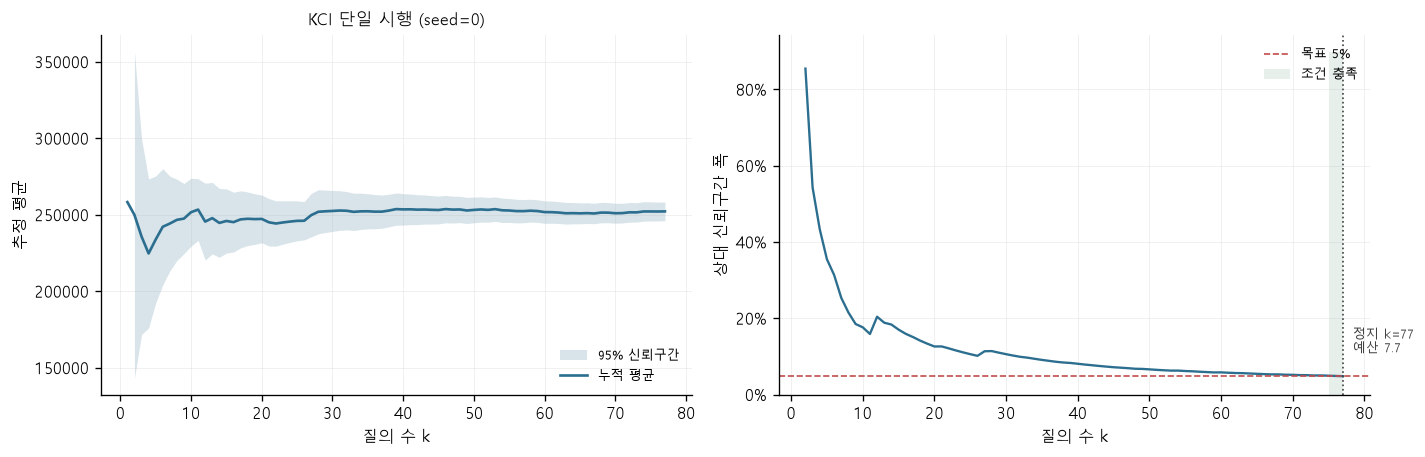

,값
converged,True
k_stop,77
eps_total,7.7
k_last,77
relative_width,0.048391
streak_count,3
covered,True
seed,0
eps,0.1
threshold,0.05


In [17]:
# ---------------------------------------------------------------------------
# 9.1 KCI 단일 시행
# ---------------------------------------------------------------------------
kci_hist, kci_final = run_kci_live(DATA, eps=EPS, threshold=THRESHOLD,
                                   streak_required=STREAK, maxq=MAXQ, seed=0)
fig, _ = plot_kci_live(kci_hist, kci_final)
_save(fig, "01_kci_single")
plt.show()

pd.Series(kci_final).to_frame("값")

## 9.2 KCI × 500회 반복 (논문 설정)

`eps_total_mean`이 KCI 방식이 제안하는 총예산이다. 절단된 시행이 평균에서 빠지므로
**반드시 `converged_rate`와 함께** 읽는다.


In [18]:
# ---------------------------------------------------------------------------
# 9.2 KCI × 500회 반복
# ---------------------------------------------------------------------------
KCI_REPS = 500
kci_trials, kci_summary, kci_traj = run_kci_repeated(
    DATA, n_reps=KCI_REPS, eps=EPS, threshold=THRESHOLD, streak_required=STREAK,
    maxq=MAXQ, alpha=ALPHA, seed0=2026, keep_trajectories=True)

pd.Series(kci_summary).to_frame("KCI × 500")

,KCI × 500
n_reps,500.000000
eps,0.100000
threshold,0.050000
streak_required,3.000000
maxq,500.000000
converged_rate,1.000000
censored_rate,0.000000
covered_rate,0.932000
elapsed_sec,0.063000
eps_total_n_valid,500.000000


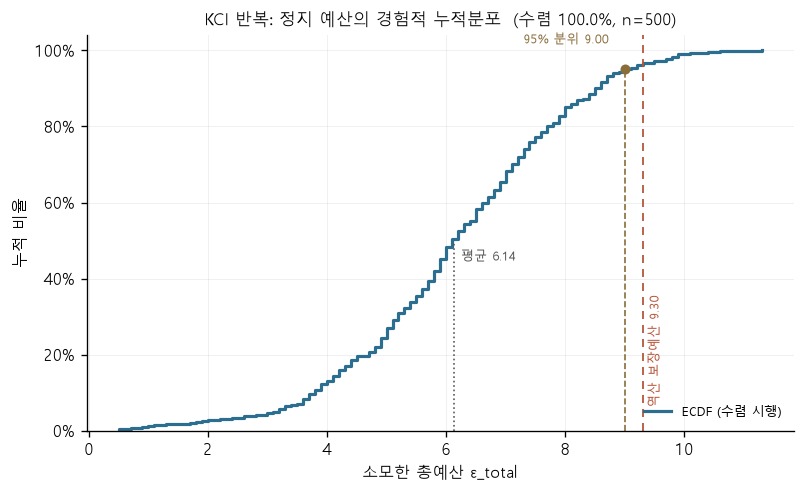

KCI 95% 분위 = 9.005  (역산 보장예산 9.30과 비교)


In [19]:
# [주 그림] 정지 예산의 ECDF — 95% 분위를 9.30과 비교
fig, ax = plot_kci_ecdf(kci_trials, kci_summary,
                        ref_lines={"역산 보장예산 9.30": 9.30})
_save(fig, "02_kci_ecdf")
plt.show()

print(f"KCI 95% 분위 = {kci_summary['eps_total_q95']:.3f}  "
      f"(역산 보장예산 9.30과 비교)")

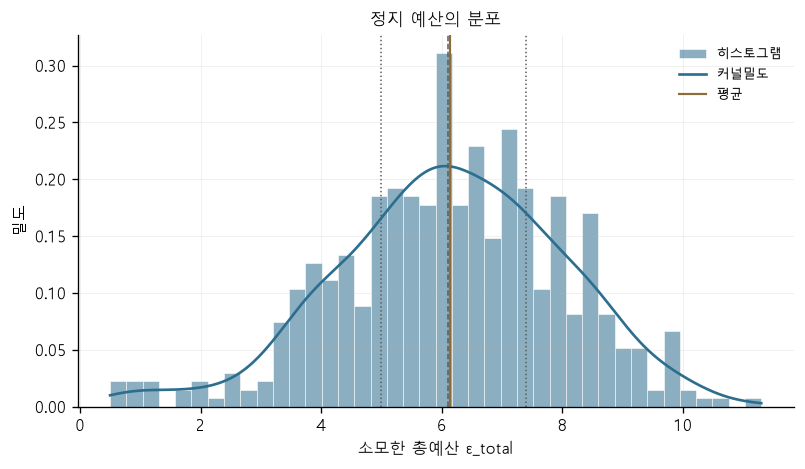

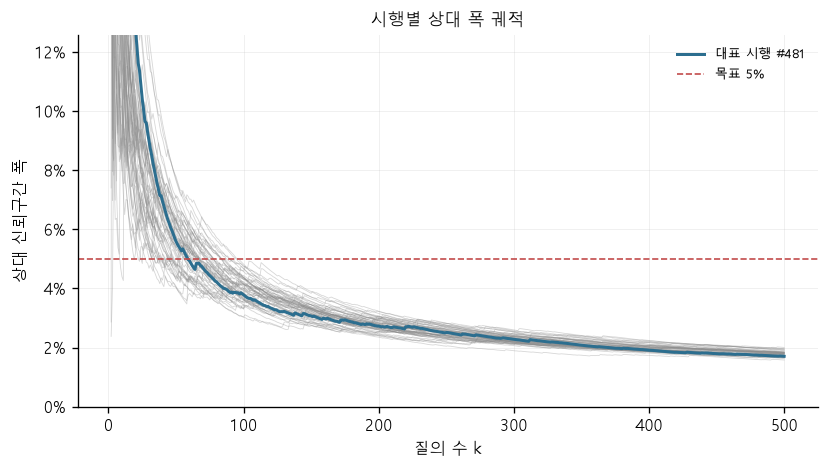

In [20]:
# 보조: 히스토그램 + 다중 궤적
fig, ax = plot_kci_hist(kci_trials, kci_summary)
_save(fig, "03_kci_hist")
plt.show()

_rep = int(np.argsort(np.abs(np.nan_to_num(kci_trials["eps_total"].to_numpy(),
                                           nan=1e9) - kci_summary["eps_total_median"]))[0])
fig, ax = plot_kci_trajectories(kci_traj, threshold=THRESHOLD, highlight=_rep)
_save(fig, "04_kci_trajectories")
plt.show()

## 9.3 KCI 메타 반복 — 예산을 하나 내놓는 절차의 재현성

바깥 반복 1회가 500회 실험을 다시 돌려 eps_mean을 하나씩 내놓는다. 그 값들의
흩어짐이 곧 "KCI 방식으로 예산을 정할 때"의 신뢰도다.

> 실행 시간을 줄이려고 예제는 `outer_reps=15, n_reps=300`으로 둔다.
> 논문용 수치는 `outer_reps=20~30, n_reps=500`으로 올려서 낸다.


In [65]:
# ---------------------------------------------------------------------------
# 9.3 KCI 메타 반복
# ---------------------------------------------------------------------------
META_OUTER = 500
META_INNER = 500

kci_meta, kci_meta_summary = run_kci_meta(
    DATA, outer_reps=META_OUTER, n_reps=META_INNER, eps=EPS, threshold=THRESHOLD,
    streak_required=STREAK, maxq=MAXQ, alpha=ALPHA, seed0_base=2026)

pd.Series(kci_meta_summary).to_frame("메타 반복 요약")

,메타 반복 요약
outer_reps,500.000000
n_reps,500.000000
eps_mean_of_means,6.267891
eps_mean_std,0.077938
eps_mean_q05,6.139950
eps_mean_q95,6.389460
eps_mean_min,6.048800
eps_mean_max,6.479200
converged_rate_mean,1.000000
total_trials,250000.000000


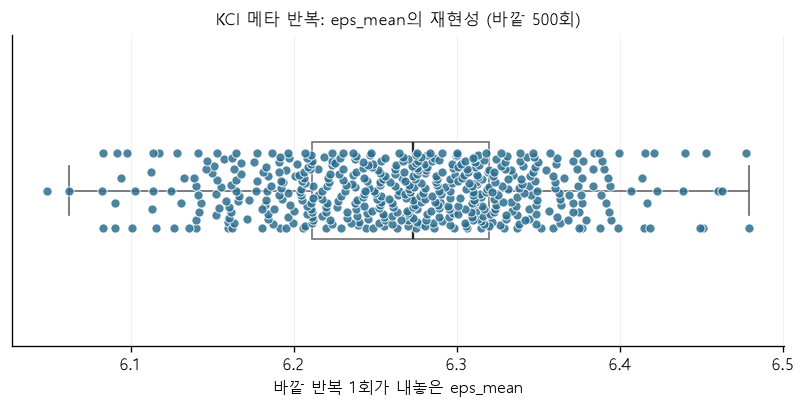

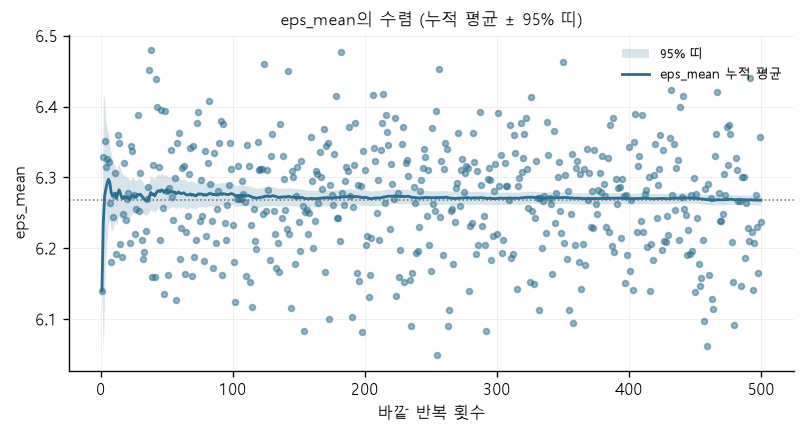

In [66]:
# 9.30 비교는 ECDF 그림이 담당한다. 여기서 다시 그리면 x축이 늘어나
# 읽으려는 점들이 뭉개진다.
fig, ax = plot_meta_strip(kci_meta)
_save(fig, "05_meta_strip")
plt.show()

fig, ax = plot_meta_fan(kci_meta)
_save(fig, "06_meta_fan")
plt.show()

## 9.4 제안 예산의 사후 검증

같은 함수로 세 가지를 평가한다.
1. **B = 9.30 단독** (빠른 확인)
2. **B = 3 / 6.1 / 9.3** (3자 대조: 첫 성공값 / KCI / 역산)
3. **메타 반복이 내놓은 eps_mean 전부** (절차 자체를 검증)


In [ ]:
# ---------------------------------------------------------------------------
# 9.4-a 예산 하나 빠른 확인
# ---------------------------------------------------------------------------
ev_single, _ = evaluate_budget(DATA, 9.30, n_trials=500, verbose=False)
ev_single[["B", "k_max", "n_success", "success_rate", "ci_lo", "ci_hi",
           "cp_lo", "cp_hi", "passed"]]

,B,k_max,n_success,success_rate,ci_lo,ci_hi,cp_lo,cp_hi,passed
0,9.2,91,477,0.954,0.931922,0.969155,0.931775,0.97062,True


In [24]:
# ---------------------------------------------------------------------------
# 9.4-b 3자 대조 (B = 3 / 6.1 / 9.3)
# ---------------------------------------------------------------------------
ev_three, ev_three_detail = evaluate_budget(DATA, [3.0, 6.1, 9.30], n_trials=500)
ev_three[["B", "k_max", "n_success", "success_rate", "ci_lo", "ci_hi",
          "cp_lo", "cp_hi", "passed"]]

,B,k_max,n_success,success_rate,ci_lo,ci_hi,cp_lo,cp_hi,passed
0,3.0,30,23,0.046,0.030845,0.068078,0.029380,0.068225,False
1,6.1,60,209,0.418,0.375553,0.461697,0.374364,0.462612,False
2,9.3,93,469,0.938,0.913340,0.955981,0.913147,0.957489,False


In [67]:
# ---------------------------------------------------------------------------
# 9.4-c 메타 반복이 내놓은 예산 전부 검증
# ---------------------------------------------------------------------------
ev_meta, _ = evaluate_budget(DATA, kci_meta["eps_total_mean"].tolist(), n_trials=500)
print(f"검증한 예산 수: {len(ev_meta)}")
print(f"합격(성공률 >= τ): {int(ev_meta['passed'].sum())} / {len(ev_meta)}")
print(f"성공률 중앙값   : {ev_meta['success_rate'].median():.3f}")
ev_meta[["B", "k_max", "success_rate", "ci_lo", "ci_hi", "passed"]].describe().loc[
    ["mean", "50%", "min", "max"]]

검증한 예산 수: 500
합격(성공률 >= τ): 0 / 500
성공률 중앙값   : 0.488


,B,k_max,success_rate,ci_lo,ci_hi
mean,6.267891,62.178,0.488312,0.444824,0.531978
50%,6.273400,62.000,0.488000,0.444445,0.531738
min,6.048800,60.000,0.402000,0.359929,0.445566
max,6.479200,64.000,0.560000,0.516197,0.602888


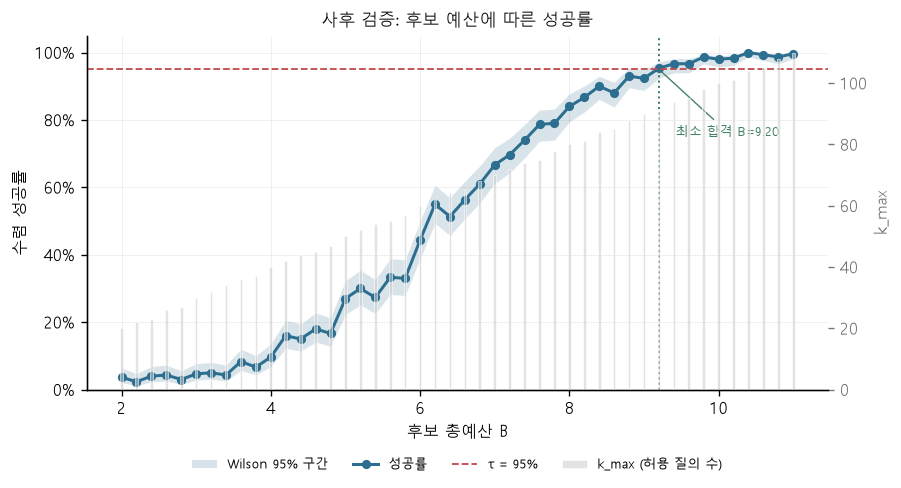

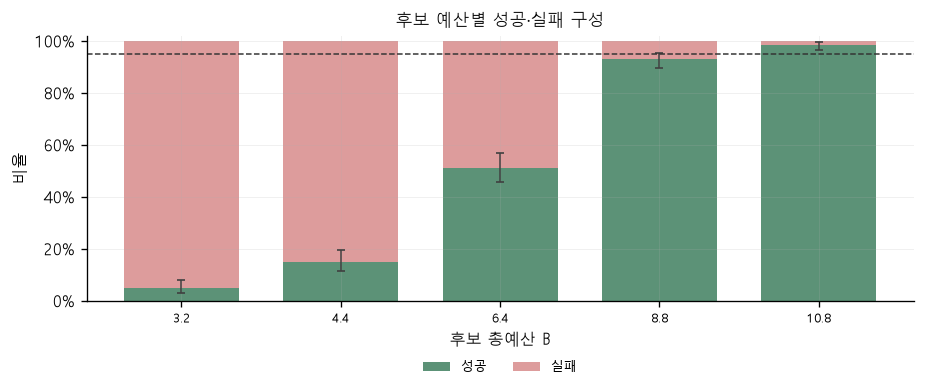

,B,k_max,n_success,success_rate,ci_lo,ci_hi,passed
0,2.0,20,11,0.036667,0.020595,0.064454,False
1,2.2,22,7,0.023333,0.011348,0.047372,False
2,2.4,23,12,0.040000,0.023027,0.068604,False
3,2.6,26,13,0.043333,0.025496,0.072717,False
4,2.8,27,9,0.030000,0.015862,0.056023,False
5,3.0,30,14,0.046667,0.027999,0.076797,False
6,3.2,32,15,0.050000,0.030532,0.080847,False
7,3.4,34,13,0.043333,0.025496,0.072717,False
8,3.6,36,25,0.083333,0.057081,0.120122,False
9,3.8,37,20,0.066667,0.043568,0.100723,False


In [68]:
# ---------------------------------------------------------------------------
# 9.4-d 후보 예산에 대한 성공률 곡선
# ---------------------------------------------------------------------------
budget_curve, _ = evaluate_budget_curve(DATA, n_trials=300,
                                        b_grid=np.round(np.arange(2.0, 11.01, 0.2), 2))
fig, _ = plot_budget_curve(budget_curve) # ,
                        #    ref_lines={"첫 성공값 3": 3.0, "KCI 6.1": 6.1,
                        #               "역산 9.3": 9.30})
_save(fig, "07_budget_curve")
plt.show()

_coarse = budget_curve[np.isclose(budget_curve["B"] % 0.4, 0.0, atol=1e-9)]
fig, ax = plot_budget_stack(_coarse)
_save(fig, "08_budget_stack")
plt.show()

budget_curve[["B", "k_max", "n_success", "success_rate", "ci_lo", "ci_hi", "passed"]].head(12)

## 9.5 역산 모델 1회 수행 — 라운드별 원자료

논문에 넣을 1회 수행은 스칼라 구현(`run_inverse_live`)으로 낸다. 라운드별 원자료와
궤적을 남겨야 하기 때문이다. `diagnostic_overrun_rounds=2`는 합격 이후 두 라운드를
**그림용으로만** 더 평가해, 성공률 곡선이 교차점에서 끊기지 않게 한다. 보고값
(final_eps, 보장 예산)은 첫 합격 라운드에 고정된다.


In [37]:
# ---------------------------------------------------------------------------
# 9.5 역산 1회 수행
# ---------------------------------------------------------------------------
inv_trials, inv_rounds, inv_traj, inv_final_eps, inv_info, inv_round_trials = run_inverse_live(
    DATA, eps=EPS, threshold=THRESHOLD, streak_required=STREAK,
    initial_eps_total=5.0, step=1.02, success_rate_threshold=TAU,
    num_runs=300, max_rounds=50, maxq=MAXQ, seed0=2026,
    collect_rounds=True, diagnostic_overrun_rounds=2, verbose=True)

pd.Series(inv_info).to_frame("역산 결과")

[라운드   1] 후보=  5.0000 | k_eval=  49 | 성공=47/300 (0.157) | 합격=False
[라운드   2] 후보=  5.1000 | k_eval=  50 | 성공=75/300 (0.250) | 합격=False
[라운드   3] 후보=  5.2020 | k_eval=  52 | 성공=85/300 (0.283) | 합격=False
[라운드   4] 후보=  5.3060 | k_eval=  53 | 성공=80/300 (0.267) | 합격=False
[라운드   5] 후보=  5.4122 | k_eval=  54 | 성공=79/300 (0.263) | 합격=False
[라운드   6] 후보=  5.5204 | k_eval=  55 | 성공=102/300 (0.340) | 합격=False
[라운드   7] 후보=  5.6308 | k_eval=  56 | 성공=105/300 (0.350) | 합격=False
[라운드   8] 후보=  5.7434 | k_eval=  57 | 성공=113/300 (0.377) | 합격=False
[라운드   9] 후보=  5.8583 | k_eval=  58 | 성공=120/300 (0.400) | 합격=False
[라운드  10] 후보=  5.9755 | k_eval=  59 | 성공=122/300 (0.407) | 합격=False
[라운드  11] 후보=  6.0950 | k_eval=  60 | 성공=141/300 (0.470) | 합격=False
[라운드  12] 후보=  6.2169 | k_eval=  62 | 성공=159/300 (0.530) | 합격=False
[라운드  13] 후보=  6.3412 | k_eval=  63 | 성공=168/300 (0.560) | 합격=False
[라운드  14] 후보=  6.4680 | k_eval=  64 | 성공=151/300 (0.503) | 합격=False
[라운드  15] 후보=  6.5974 | k_eval=  65 | 성공=150/300 (0.5

,역산 결과
status,converged
final_eps,6.15
final_eps_raw,6.147059
eps_total_guaranteed,9.0
pass_round,31
success_rate,0.963333
n_success,289
num_runs,300
rounds_used,33
success_rate_threshold,0.95


In [28]:
inv_rounds[["round", "candidate_eps_total", "k_max", "k_eval", "eps_total_eval",
            "n_success", "success_rate", "passed", "is_overrun"]]

,round,candidate_eps_total,k_max,k_eval,eps_total_eval,n_success,success_rate,passed,is_overrun
0,1,5.000000,49,49,4.9,31,0.155,False,False
1,2,5.150000,51,51,5.1,49,0.245,False,False
2,3,5.304500,53,53,5.3,62,0.310,False,False
3,4,5.463635,54,54,5.4,48,0.240,False,False
4,5,5.627544,56,56,5.6,63,0.315,False,False
5,6,5.796370,57,57,5.7,68,0.340,False,False
6,7,5.970261,59,59,5.9,82,0.410,False,False
7,8,6.149369,61,61,6.1,98,0.490,False,False
8,9,6.333850,63,63,6.3,98,0.490,False,False
9,10,6.523866,65,65,6.5,109,0.545,False,False


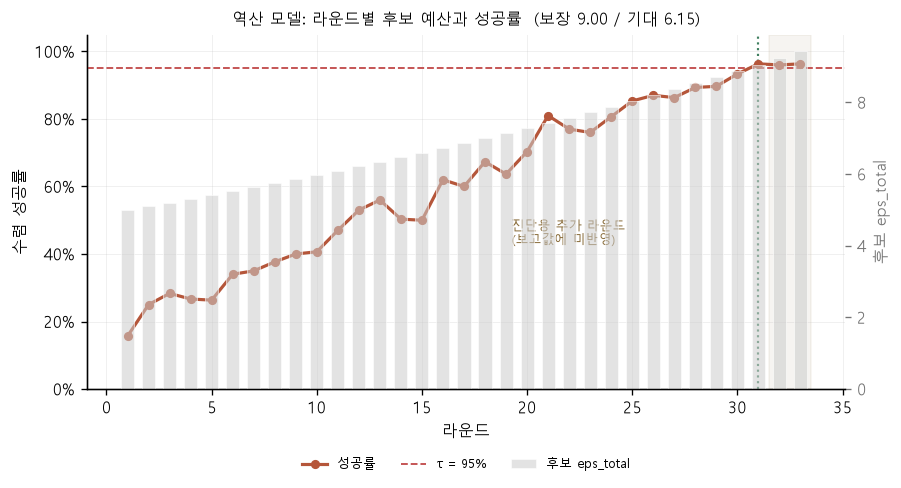

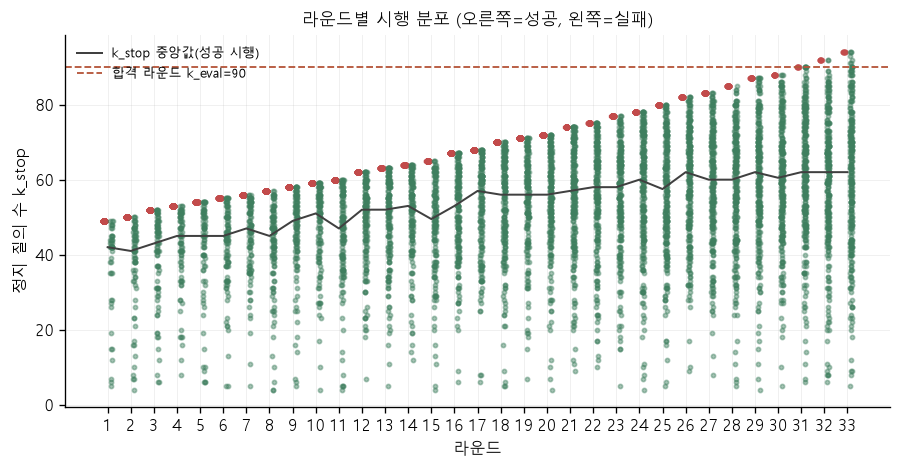

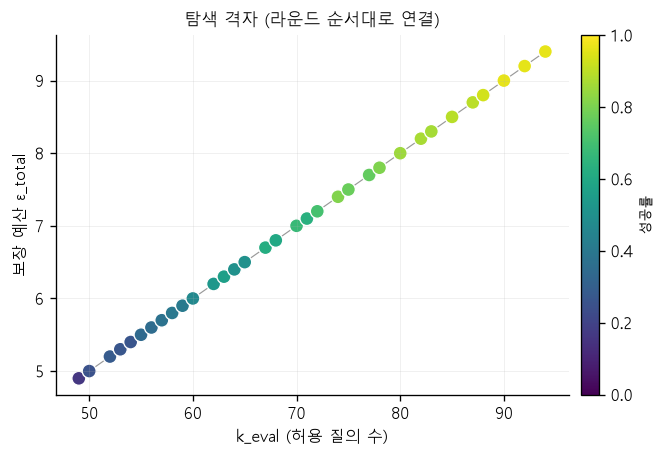

In [38]:
fig, _ = plot_inverse_rounds(inv_rounds, inv_info)
_save(fig, "09_inverse_rounds")
plt.show()

fig, ax = plot_inverse_round_strip(inv_round_trials, inv_info)
_save(fig, "10_inverse_round_strip")
plt.show()

fig, ax = plot_inverse_scatter(inv_rounds)
_save(fig, "11_inverse_scatter")
plt.show()

In [51]:
# ============================================================================
# §6-b. 역산 모델 그림 — inv_* 객체를 그대로 받아 그린다
# ============================================================================
from matplotlib.patches import Patch
PALETTE["warn"] = "#C8871B"


def _wilson_rate_band(n_success, n_runs, z=1.959963984540054):
    """라운드별 성공률의 Wilson 구간(하한, 상한) 배열."""
    k = np.asarray(n_success, dtype=float)
    n = float(n_runs)
    p = k / n
    denom = 1.0 + z * z / n
    centre = (p + z * z / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return np.clip(centre - half, 0, 1), np.clip(centre + half, 0, 1)


def plot_inverse_rounds(round_summary, info=None, tau=TAU, title=None):
    """[주 그림] 탐색 격자 위의 성공률 — 후보 예산(x)과 성공률(y)을 한 패널에 담는다.

    위/아래 두 패널로 나누면 같은 x축(라운드)을 두 번 쓰고, 읽는 사람이 위아래를
    오가며 두 값을 머릿속에서 맞춰야 한다. 여기서는 **탐색 변수인 후보 예산을 x축으로
    내려** 두 변수를 한 좌표계에 놓았다. 라운드는 점의 순서이므로 선을 따라 읽으면
    되고, 주요 라운드 번호만 점 위에 적었다.

    읽는 법
      오른쪽으로 갈수록 라운드가 진행된 것이다(후보 예산이 3%씩 증가).
      세로는 판정 성공률. 띠는 라운드별 Wilson 95% 구간이다.
      붉은 파선 τ를 처음 넘는 점이 합격 라운드 — 그 예산이 최소 보장 예산이다.

    축이 하나씩이므로 이중축에서 생기던 "어느 쪽 눈금을 읽어야 하나" 문제가 없다.
    오른쪽 진단용 라운드는 음영으로 표시하고 보고값에 영향이 없음을 명시한다.

    >>> fig, ax = plot_inverse_rounds(inv_rounds, inv_info)
    """
    d = round_summary.sort_values("round").reset_index(drop=True)
    n_runs = int(info["num_runs"]) if info and "num_runs" in info else int(d["n_success"].max())
    lo, hi = _wilson_rate_band(d["n_success"], n_runs)

    x = d["eps_total_eval"].to_numpy(float)
    r = d["success_rate"].to_numpy(float)
    over = d[d["is_overrun"]]

    fig, ax = plt.subplots(figsize=(7.8, 4.6))
    ax.axhspan(0, tau, color="0.955", lw=0, zorder=0)          # 미달 영역
    if not over.empty:                                        # 진단용 라운드 구간
        ax.axvspan(over["eps_total_eval"].min() - 0.12, x.max() + 0.25,
                   color=PALETTE["accent"], alpha=0.09, lw=0, zorder=0)

    ax.fill_between(x, lo, hi, color=PALETTE["inverse"], alpha=0.16, lw=0,
                    label="Wilson 95% 구간", zorder=2)
    ax.plot(x, r, "-o", color=PALETTE["inverse"], lw=1.7, ms=4.0, mfc="white", mew=1.0,
            label="판정 성공률", zorder=4)
    ax.axhline(tau, color=PALETTE["fail"], lw=1.2, ls="--", label=f"τ = {tau:.0%}",
               zorder=3)

    # 주요 라운드 번호를 점 위에 직접 적어, x축이 라운드의 진행임을 알린다
    for _, row in d.iterrows():
        if int(row["round"]) in (1, 5, 10, 15, 20) or row["passed"]:
            ax.annotate(f"R{int(row['round'])}", xy=(row["eps_total_eval"], row["success_rate"]),
                        xytext=(0, -13), textcoords="offset points", ha="center",
                        fontsize=7, color="0.45")

    passed = d[d["passed"] & (~d["is_overrun"])]
    if not passed.empty:
        p0 = passed.iloc[0]
        x0, r0 = float(p0["eps_total_eval"]), float(p0["success_rate"])
        l0, h0 = lo[d["round"] == int(p0["round"])][0], hi[d["round"] == int(p0["round"])][0]
        ax.plot([x0], [r0], "o", ms=9, color=PALETTE["pass"], zorder=6)
        ax.annotate(f"합격 R{int(p0['round'])} · 보장 {x0:.2f}\n"
                    f"{r0:.1%}  [{l0:.1%}, {h0:.1%}]",
                    xy=(x0, r0), xytext=(-14, 12), textcoords="offset points",
                    fontsize=8.5, color=PALETTE["pass"], ha="right", va="bottom")

    if not over.empty:
        ax.annotate("진단용 라운드\n(보고값 미반영)",
                    xy=(over["eps_total_eval"].mean(), 0.30), ha="center", fontsize=7.5,
                    color=PALETTE["accent"])

    ax.annotate("", xy=(x.max() + 0.12, 0.055), xytext=(x.min(), 0.055),
                arrowprops=dict(arrowstyle="->", color="0.55", lw=1.0))
    ax.annotate("라운드 진행 (예산 3%씩 증가)", xy=((x.min() + x.max()) / 2, 0.075),
                ha="center", fontsize=7.5, color="0.45")

    ax.set_xlim(x.min() - 0.25, x.max() + 0.35)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("후보 총예산 ε_total  (= k_eval × ε)")
    ax.set_ylabel("판정 성공률")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_title(title or "예산을 올리면 성공률이 오르고, 처음 τ를 넘는 예산이 보장 예산이 된다",
                 fontsize=10, loc="left")
    ax.legend(loc="lower right", fontsize=8)
    _style(ax)
    fig.tight_layout()
    return fig, ax


def plot_inverse_budget_realization(round_trials, info=None, title=None):
    """[주 그림] 합격 라운드의 실현 소모 분포 위에 "예약 상한"을 세운다.

    위 패널 : 실현 소모(ε × k_stop)의 히스토그램.
              성공 시행은 각자의 k_stop에서 멈추고, 미수렴 시행은 상한에 붙는다.
    아래 패널: 같은 시행들의 1차원 스트립. 두 선 사이의 음영이 실현되지 않은 예약분이다.

    두 세로선의 성격이 다르다는 점이 이 그림의 전부다.
      실현 중앙값 (실선) : 실제로 소모된 예산. 질의 k건을 던진 결과다.
      보장 예산 (점선)   : 소모량이 아니라 예약 상한. 극소수 시행만 여기 닿는다.

    >>> fig, (ax, ax2) = plot_inverse_budget_realization(inv_round_trials, inv_info)
    """
    eps = float(info["eps"]) if info and "eps" in info else EPS
    d = round_trials[~round_trials["is_overrun"]].copy()
    r0 = int(info["pass_round"]) if info and info.get("pass_round") is not None else int(d["round"].max())
    d = d[d["round"] == r0]

    cap = float(d["eps_total_eval"].iloc[0])
    d["realized"] = np.where(d["success"], d["k_stop"] * eps, cap)
    succ = d.loc[d["success"], "realized"].to_numpy(float)
    fail = d.loc[~d["success"], "realized"].to_numpy(float)
    med = float(np.median(succ)) if succ.size else np.nan

    fig, (ax, ax2) = plt.subplots(
        2, 1, figsize=(7.8, 5.0), sharex=True,
        gridspec_kw=dict(height_ratios=[2.3, 1.0], hspace=0.16))

    # ---------------------------------------------------------- 위: 히스토그램
    bins = np.arange(0, cap + 0.8, 0.4)
    ax.hist(succ, bins=bins, color=PALETTE["kci"], alpha=0.72, edgecolor="white",
            lw=0.7, label="성공 시행 (k_stop에서 정지)")
    if fail.size:
        ax.hist(fail, bins=[cap - 0.2, cap + 0.2], color=PALETTE["fail"], alpha=0.90,
                edgecolor="white", lw=0.7,
                label=f"상한 도달 {fail.size}건 (k_stop 없음 = 미수렴)")
    top = ax.get_ylim()[1]

    ax.axvline(med, color=PALETTE["kci"], lw=1.8)
    ax.annotate(f"실현 중앙값 {med:.1f}\n(질의 {int(round(med / eps))}건에서 정지)",
                xy=(med, top * 0.72), xytext=(-6, 0), textcoords="offset points",
                fontsize=8.5, color=PALETTE["kci"], ha="right", va="center")
    ax.axvline(cap, color=PALETTE["inverse"], lw=1.8, ls="--")
    ax.annotate(f"보장 예산 {cap:.1f} = 예약 상한\n(소모량이 아니라 최대 허용치)",
                xy=(cap, top * 0.45), xytext=(8, 0), textcoords="offset points",
                fontsize=8.5, color=PALETTE["inverse"], ha="left", va="center")

    ax.set_ylabel("시행 수")
    ax.set_title(title or f"합격 라운드 {r0}의 시행 {len(d)}건 — "
                          f"{len(succ)}건은 상한 아래에서 멈추고 {fail.size}건만 상한에 닿는다",
                 fontsize=10, loc="left")
    ax.legend(loc="upper left", fontsize=8)
    _style(ax)

    # ------------------------------------------------------- 아래: 1차원 스트립
    jit = np.random.default_rng(3).uniform(-0.16, 0.16, succ.size)
    ax2.plot(succ, jit, "o", ms=3.2, color=PALETTE["kci"], alpha=0.45, mew=0)
    if fail.size:
        ax2.plot(fail, np.zeros(fail.size), "o", ms=5.0, color=PALETTE["fail"],
                 alpha=0.90, mew=0)
    ax2.axvspan(med, cap, color=PALETTE["accent"], alpha=0.10, lw=0)
    ax2.annotate("실현되지 않은 예약분\n(다른 질의에 재사용 불가)",
                 xy=(med + (cap - med) / 2, 0.42), ha="center", fontsize=8,
                 color=PALETTE["accent"])
    ax2.set_yticks([])
    ax2.set_ylim(-0.55, 0.62)
    ax2.set_xlim(0, cap + 0.7)
    ax2.set_xlabel("총예산 ε  =  ε × 실제 질의 수")
    _style(ax2)
    ax2.grid(False)
    # 공유 x축 2단 구성은 tight_layout과 상성이 나빠 경고가 난다 -> 여백 직접 지정
    fig.subplots_adjust(left=0.085, right=0.985, top=0.905, bottom=0.10, hspace=0.16)
    return fig, (ax, ax2)


def plot_inverse_caterpillar(round_summary, info=None, tau=TAU, title=None):
    """[주 그림] 라운드별 성공률과 Wilson 95% 구간(caterpillar plot).

    탐색 격자 산점도를 대체한다. 예전 그림은 x=k_eval, y=k_eval×ε이라 두 축이
    결정적으로 같은 값이었고, 색만이 정보를 나르고 있었다. 여기서는 x를 예산,
    y를 판정 성공률로 두고, 판정의 불확실성을 세로 구간으로 드러낸다.

    분류 기준
      확실 : 구간 하한까지 τ 이상 (이 예산이면 안전)
      경계 : 점추정만 τ 이상이고 구간이 τ를 가로지름 (판정이 흔들림)
      미달 : 점추정도 τ 미만

    합격 판정이 τ 바로 위에서 내려졌다면, 그 판정은 시드를 바꾸면 뒤집힐 수 있다는
    사실이 그림 하나로 보인다.

    >>> fig, ax = plot_inverse_caterpillar(inv_rounds, inv_info)
    """
    d = round_summary[~round_summary["is_overrun"]].sort_values("eps_total_eval")
    n_runs = int(info["num_runs"]) if info and "num_runs" in info else int(d["n_success"].max())
    lo, hi = _wilson_rate_band(d["n_success"], n_runs)
    r = d["success_rate"].to_numpy()
    x = d["eps_total_eval"].to_numpy()

    sure = lo >= tau
    border = (r >= tau) & (lo < tau)
    miss = ~(sure | border)

    fig, ax = plt.subplots(figsize=(7.4, 4.4))
    ax.axhspan(0, tau, color="0.94", lw=0, zorder=0)
    ax.plot(x, r, color="0.85", lw=1.0, zorder=1)
    handles, labels = [], []
    for mask, kw, lab in (
        (miss, dict(fmt="o", ms=4.5, color="0.55", ecolor="0.75", elinewidth=1.0,
                    capsize=0), "미달"),
        (border, dict(fmt="o", ms=7, color=PALETTE["warn"], ecolor=PALETTE["warn"],
                      elinewidth=1.8, capsize=3), "점추정만 τ 이상 (경계)"),
        (sure, dict(fmt="o", ms=7, color=PALETTE["pass"], ecolor=PALETTE["pass"],
                    elinewidth=1.8, capsize=3), "구간 하한도 τ 이상 (확실)"),
    ):
        if mask.any():
            eb = ax.errorbar(x[mask], r[mask], yerr=[r[mask] - lo[mask], hi[mask] - r[mask]],
                             zorder=5, **kw)
            handles.append(eb.lines[0])
            labels.append(lab)
    ax.axhline(tau, color=PALETTE["fail"], lw=1.2, ls="--", label=f"τ = {tau:.0%}")

    if not sure.any() and border.any():
        ax.annotate("구간 하한이 τ를 넘는 라운드가 없다\n→ 합격은 시드에 따라 뒤집힐 수 있다",
                    xy=(0.98, 0.06), xycoords="axes fraction", ha="right", fontsize=8,
                    color=PALETTE["warn"])

    ax.set_xlabel("라운드의 보장 예산 ε_total (= k_eval × ε)")
    ax.set_ylabel("판정 성공률")
    ax.set_ylim(0, 1.03)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_title(title or "합격 판정은 τ 바로 위에서 흔들린다 — 라운드별 성공률과 95% 구간",
                 fontsize=10, loc="left")
    h0, l0 = ax.get_legend_handles_labels()
    ax.legend(h0 + handles, l0 + labels, loc="upper left", fontsize=8)
    _style(ax)
    fig.tight_layout()
    return fig, ax


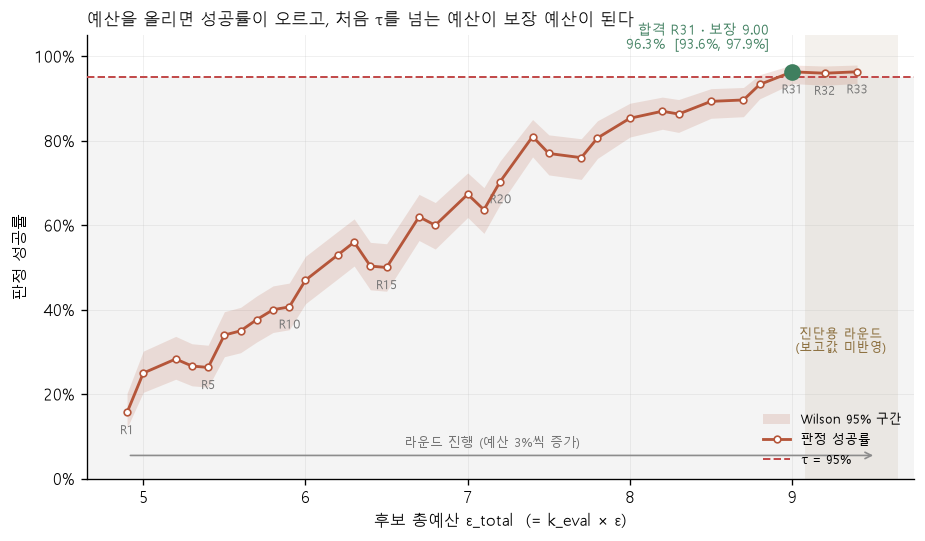

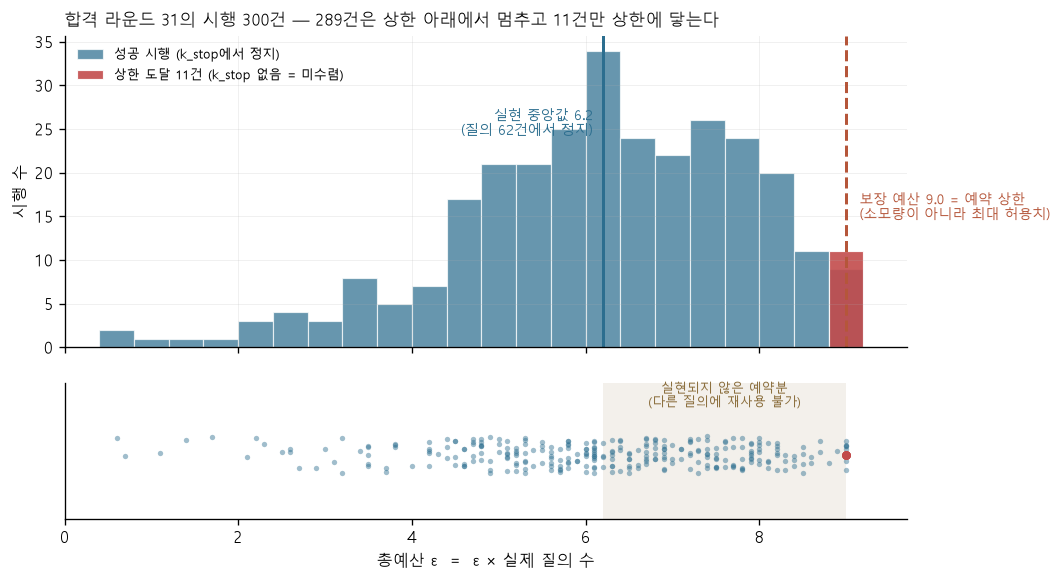

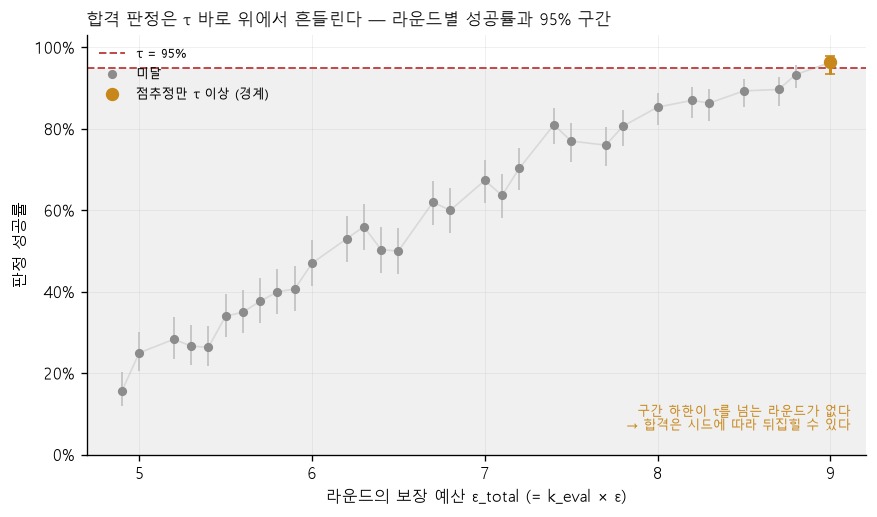

In [52]:
# (1) 한 패널: x=후보 예산, y=성공률 (이중축 없이 축 하나씩)
fig, _ = plot_inverse_rounds(inv_rounds, inv_info)
_save(fig, "09_inverse_rounds")
plt.show()

# (2) 
fig, _ = plot_inverse_budget_realization(inv_round_trials, inv_info)
_save(fig, "10_inverse_budget_realization")
plt.show()

# (3) caterpillar: 판정이 τ 경계에서 얼마나 흔들리는가
fig, ax = plot_inverse_caterpillar(inv_rounds, inv_info)
_save(fig, "11_inverse_caterpillar")
plt.show()

## 9.6 num_runs 스윕 (CAPRI Fig. 5)

num_runs를 키우면 final eps의 분포가 좁아지는지 확인한다. 예제는 `reps=40`이고,
논문에서는 `reps=100~500`을 쓴다.


In [41]:
# ---------------------------------------------------------------------------
# 9.6 num_runs 스윕
# ---------------------------------------------------------------------------
N_LIST = (1, 10, 50, 100, 200, 300, 500, 700, 1000)
nr_res, nr_summary = run_num_runs_sweep(
    DATA["true_mean"], DATA["delta"], eps=EPS, threshold=THRESHOLD,
    streak_required=STREAK, n_list=N_LIST, reps=40, maxq=200, seed0=2026)

nr_summary

num_runs=   1:    0.1초, 절단=0
num_runs=  10:    0.3초, 절단=0
num_runs=  50:    0.8초, 절단=0
num_runs= 100:    1.2초, 절단=0
num_runs= 200:    2.3초, 절단=0
num_runs= 300:    3.4초, 절단=0
num_runs= 500:    5.5초, 절단=0
num_runs= 700:    7.6초, 절단=0
num_runs=1000:   12.1초, 절단=0


,n_valid,median,mean,std,q05,q95,q25,q75,iqr,n_nan
num_runs,,,,,,,,,,
1,40,5.3,5.3625,0.407423,4.90,6.100,5.100,5.6,0.500,0
10,40,8.2,8.2400,0.600769,7.29,9.300,8.000,8.5,0.500,0
50,40,9.0,9.0000,0.408248,8.20,9.515,8.700,9.3,0.600,0
100,40,9.0,9.0550,0.254145,8.69,9.300,9.000,9.3,0.300,0
200,40,9.0,9.1450,0.181094,9.00,9.310,9.000,9.3,0.300,0
300,40,9.3,9.1550,0.173870,9.00,9.300,9.000,9.3,0.300,0
500,40,9.3,9.1950,0.144914,9.00,9.300,9.000,9.3,0.300,0
700,40,9.3,9.2300,0.138119,9.00,9.300,9.225,9.3,0.075,0
1000,40,9.3,9.2525,0.121924,9.00,9.300,9.300,9.3,0.000,0


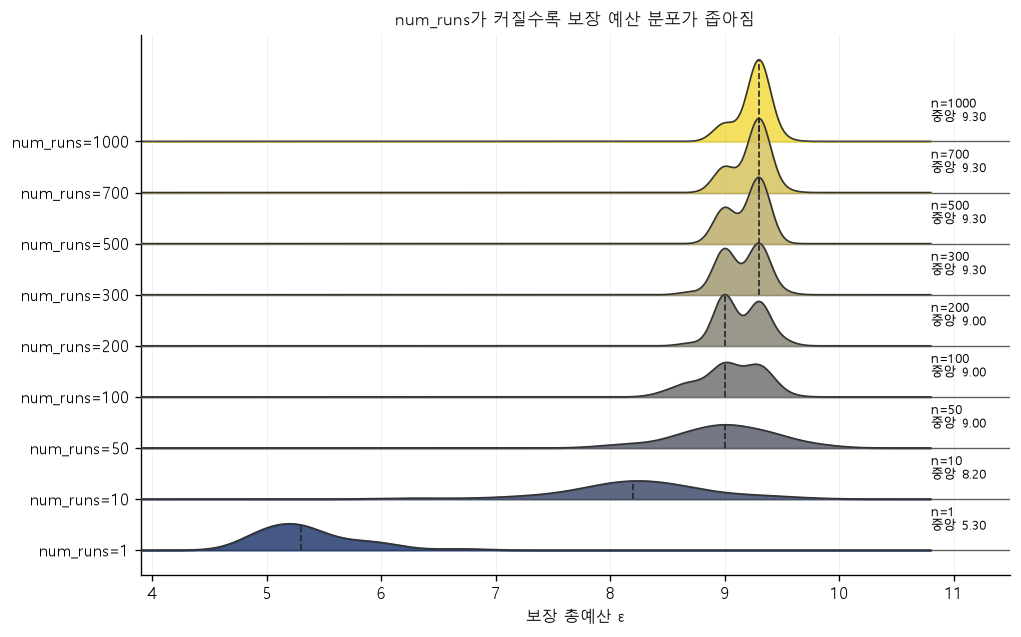

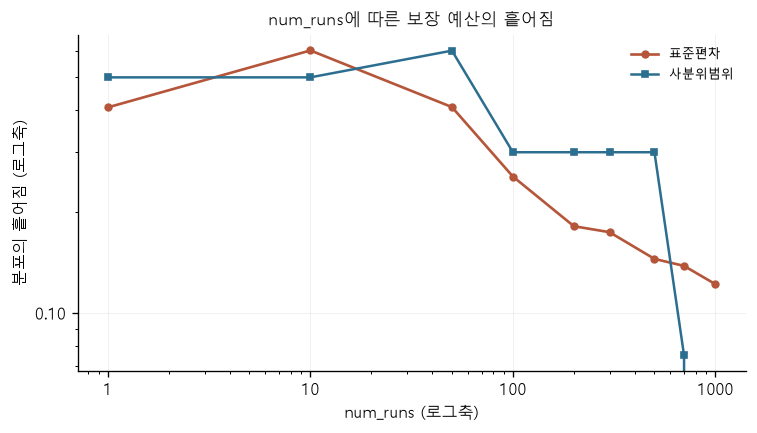

In [42]:
fig, ax = plot_ridgeline(nr_res, title="num_runs가 커질수록 보장 예산 분포가 좁아짐")
_save(fig, "12_num_runs_ridgeline")
plt.show()

fig, ax = plot_num_runs_spread(nr_summary)
_save(fig, "13_num_runs_spread")
plt.show()

## 9.7 역산 seed 스윕

시드를 바꿔도 결론이 남는지, num_runs를 키우면 시드 간 흩어짐이 줄어드는지 확인한다.
이 결과는 §9.6과 **같은 방향**을 가리켜야 한다. 그것이 그 주장의 독립 증거다.


In [69]:
# ---------------------------------------------------------------------------
# 9.7 역산 seed 스윕
# ---------------------------------------------------------------------------
seed_df = run_inverse_seed_sweep(
    DATA["true_mean"], DATA["delta"], num_runs_list=(10, 50, 300, 500), n_seeds=150,
    eps=EPS, threshold=THRESHOLD, streak_required=STREAK, maxq=MAXQ, seed0_base=2026)

seed_summary = summarize_seed_sweep(seed_df)
seed_summary[["num_runs", "eps_guaranteed_n", "eps_guaranteed_median",
              "eps_guaranteed_std", "eps_guaranteed_iqr", "converged_rate"]]

,num_runs,eps_guaranteed_n,eps_guaranteed_median,eps_guaranteed_std,eps_guaranteed_iqr,converged_rate
0,10,150,8.2,0.650904,1.0,1.0
1,50,150,9.0,0.367036,0.6,1.0
2,300,150,9.3,0.168127,0.0,1.0
3,500,150,9.3,0.127374,0.0,1.0


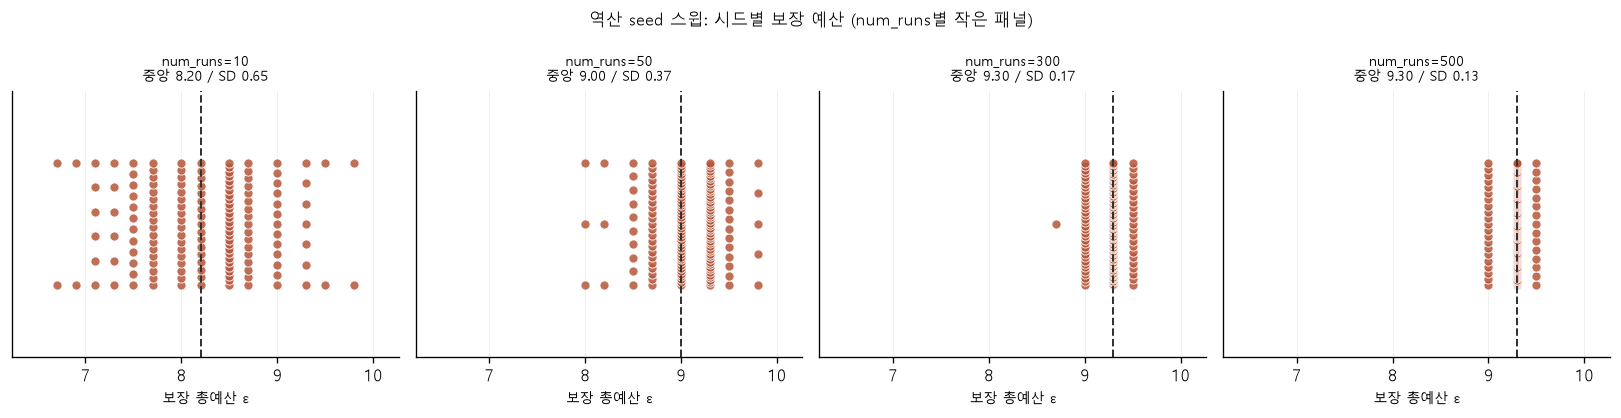

In [70]:
fig, _ = plot_seed_sweep_beeswarm(seed_df)
_save(fig, "14_seed_beeswarm")
plt.show()

# fig, ax = plot_seed_sweep_heatmap(seed_df)
# _save(fig, "15_seed_heatmap")
# plt.show()

In [58]:
def plot_seed_sweep_hist(df, col="eps_guaranteed", title=None):
    """[주 그림] num_runs별 보장 예산 히스토그램 — 시드 분포가 한 칸으로 모이는 과정.

    앞선 beeswarm은 점을 옆으로 밀어 겹침만 풀 뿐, "분포가 좁아진다"는 주장을
    세로로 읽어야 했다. 히스토그램은 그 주장을 막대 높이 하나로 보여준다.

    구간 설정이 이 그림의 핵심이다. 보장 예산은 연속값이 아니라 후보 예산 격자
    (ε 간격의 이산값: 7.5, 7.7, …, 9.5)에만 놓이므로, 임의 구간을 잡으면 막대가
    사실을 왜곡한다. 여기서는 **관측된 격자 자체를 구간으로** 쓴다. 시드가 12개씩
    뿐이라 임의 bins로는 히스토그램이 성립하지 않는다는 점도 이 방식이 해결한다.

    세 패널은 x·y 축을 공유한다. 그래야 "왼쪽은 넓게 퍼지고 오른쪽은 한 칸에 몰린다"가
    패널 간 비교로 읽힌다. 가장 높은 막대만 진하게 칠해 최빈 구간을 표시한다.

    >>> fig, axes = plot_seed_sweep_hist(seed_df)
    """
    d = df.dropna(subset=[col]).copy()
    nrs = sorted(d["num_runs"].unique())
    lattice = np.sort(d[col].unique())                 # 관측된 후보 예산 격자 = 구간
    gaps = np.diff(lattice)
    width = float(min(gaps)) * 0.6 if gaps.size else 0.1
    width = min(width, 0.14)

    fig, axes = plt.subplots(1, len(nrs), figsize=(3.0 * len(nrs), 3.4),
                             sharex=True, sharey=True, squeeze=False)
    axes = axes[0]
    ymax = max((d.loc[d["num_runs"] == n, col] == L).sum()
               for n in nrs for L in lattice)

    for ax, nr in zip(axes, nrs):
        v = d.loc[d["num_runs"] == nr, col]
        counts = np.array([(v == L).sum() for L in lattice])
        colors = [PALETTE["inverse"] if c == counts.max() else "#CDB09A" for c in counts]
        ax.bar(lattice, counts, width=width, color=colors, edgecolor="white", lw=0.8)
        ax.set_title(f"num_runs={nr}\n중앙 {v.median():.2f} / SD {v.std(ddof=1):.2f}",
                     fontsize=8.5)
        ax.set_xlabel("보장 총예산 ε", fontsize=8.5)
        ax.set_ylim(0, ymax * 1.08)
        _style(ax)

    axes[0].set_ylabel("시드 수")
    fig.suptitle(title or f"num_runs가 커질수록 시드별 보장 예산이 한 칸으로 모인다 "
                          f"(시드 {len(d) // len(nrs)}개씩)", fontsize=10)
    fig.tight_layout()
    return fig, axes


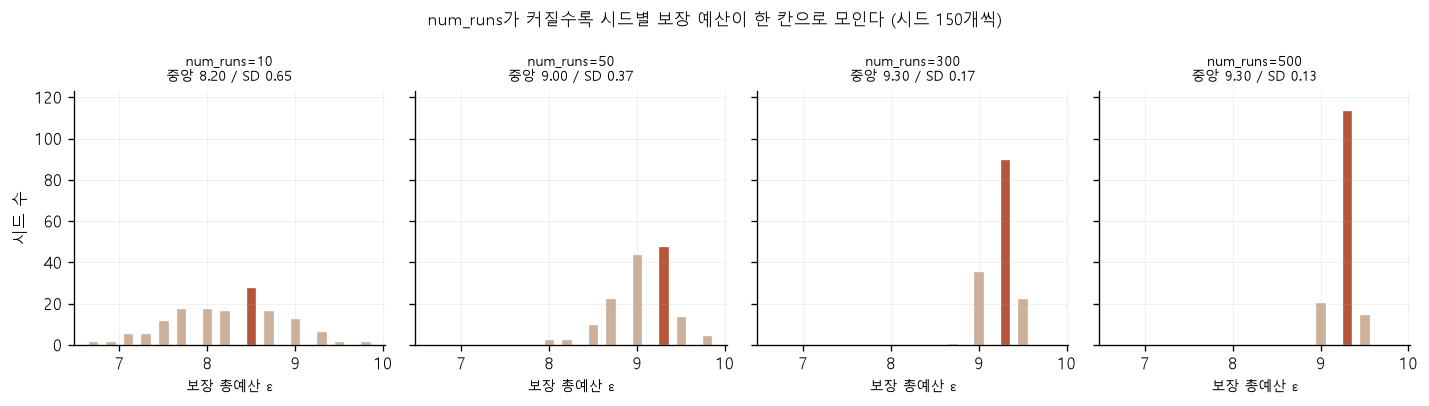

In [71]:
fig, _ = plot_seed_sweep_hist(seed_df)
_save(fig, "14_seed_hist")
plt.show()


## 9.8 내보내기

모든 표를 `outputs/`에 CSV로 쓴다. 그림은 각자의 셀에서 이미 저장했다.


In [34]:
# ---------------------------------------------------------------------------
# 9.8 CSV 내보내기
# ---------------------------------------------------------------------------
_artifacts = {
    "kci_trials": kci_trials,
    "kci_summary": pd.Series(kci_summary).to_frame("value"),
    "kci_meta": kci_meta,
    "kci_meta_summary": pd.Series(kci_meta_summary).to_frame("value"),
    "budget_eval_single": ev_single,
    "budget_eval_three": ev_three,
    "budget_eval_meta": ev_meta,
    "budget_curve": budget_curve,
    "inverse_rounds": inv_rounds,
    "inverse_round_trials": inv_round_trials,
    "num_runs_res": nr_res,
    "num_runs_summary": nr_summary.reset_index(),
    "seed_sweep": seed_df,
    "seed_sweep_summary": seed_summary,
}
for _name, _df in _artifacts.items():
    _df.to_csv(OUTPUT_DIR / f"{_name}.csv", index=(_name in ("num_runs_summary", "seed_sweep_summary")))
print("\n".join(f"  {p.name:34s} {p.stat().st_size:>8,} B"
                for p in sorted(OUTPUT_DIR.glob('*.csv'))))

  budget_curve.csv                      6,194 B
  budget_eval_meta.csv                  2,194 B
  budget_eval_single.csv                  241 B
  budget_eval_three.csv                   495 B
  inverse_round_trials.csv            349,002 B
  inverse_rounds.csv                    1,716 B
  kci_meta.csv                          3,826 B
  kci_meta_summary.csv                    150 B
  kci_summary.csv                         238 B
  kci_trials.csv                       28,563 B
  num_runs_res.csv                      7,863 B
  num_runs_summary.csv                    473 B
  seed_sweep.csv                        1,666 B
  seed_sweep_summary.csv                  407 B
  survey.csv                            7,452 B
  unit_check.csv                       17,751 B


In [35]:
# ---------------------------------------------------------------------------
# 9.9 한 장 요약
# ---------------------------------------------------------------------------
_nr = nr_summary.reset_index()
_summary_rows = [
    ("KCI ×500: eps_total 평균", f"{kci_summary['eps_total_mean']:.3f}"),
    ("KCI ×500: eps_total 중앙값", f"{kci_summary['eps_total_median']:.3f}"),
    ("KCI ×500: 95% 분위", f"{kci_summary['eps_total_q95']:.3f}"),
    ("KCI ×500: 수렴률", f"{kci_summary['converged_rate']:.3f}"),
    ("KCI ×500: 신뢰구간 포함률", f"{kci_summary['covered_rate']:.3f}"),
    (f"메타 ({META_OUTER}×{META_INNER}): eps_mean의 SD",
     f"{kci_meta_summary['eps_mean_std']:.4f}"),
    ("검증 B=9.30 성공률", f"{float(ev_single['success_rate'].iloc[0]):.3f}"),
    ("역산: 보장 예산", f"{inv_info['eps_total_guaranteed']}"),
    ("역산: 기대 소모량", f"{inv_info['final_eps']}"),
    ("num_runs=1 흩어짐 SD",
     f"{float(_nr.loc[_nr['num_runs']==1,'std'].iloc[0]):.3f}"),
    ("num_runs=최대 흩어짐 SD", f"{float(_nr['std'].iloc[-1]):.3f}"),
]
pd.DataFrame(_summary_rows, columns=["항목", "값"]).set_index("항목")

,값
항목,
KCI ×500: eps_total 평균,6.140
KCI ×500: eps_total 중앙값,6.100
KCI ×500: 95% 분위,9.005
KCI ×500: 수렴률,1.000
KCI ×500: 신뢰구간 포함률,0.932
메타 (15×300): eps_mean의 SD,0.0995
검증 B=9.30 성공률,0.968
역산: 보장 예산,9.5
역산: 기대 소모량,6.1


In [36]:
# ---------------------------------------------------------------------------
# 9.10 그림 글자 깨짐 전수 점검
# ---------------------------------------------------------------------------
# _save()가 저장 시점마다 막지만, 폰트가 조용히 바뀌는 경우까지 확인하기 위해
# 저장된 PNG를 다시 열어 한글 글리프가 실제로 그려졌는지 본다.
from matplotlib import image as mpimg

_PNGS = sorted(OUTPUT_DIR.glob("*.png"))
_blank = []
for _p in _PNGS:
    _im = mpimg.imread(_p)
    if _im.size == 0 or float(_im.std()) < 1e-4:      # 거의 단색 = 그리기 실패
        _blank.append(_p.name)

print(f"그림 {len(_PNGS)}장 확인 | 비정상 {len(_blank)}장")
print(f"사용 폰트: {plt.rcParams['font.family']}")
assert not _blank, f"비어 있는 그림: {_blank}"
print("모든 그림이 정상적으로 저장되었습니다.")

그림 15장 확인 | 비정상 0장
사용 폰트: ['Malgun Gothic', 'DejaVu Sans']
모든 그림이 정상적으로 저장되었습니다.
